# Module 3 · Analysis: a small neural network, one explanation, and one AI weather model

**Does a small neural network beat the model that won Module 2 — and which inputs moved its call?** Same CESM2 LENS member-winters,
same split, same spine; then one AI weather model, one case, two conditions for distrust.

No Binder badge for this module: the Binder route (the cookbook repository `glenbuchanan/cesm2-lens-ml-readiness-cookbook`) covers Module 2's notebook only; run Module 3 locally or on the NSF NCAR JupyterHub. Run this notebook from `course/environment.yml` (conda-forge, pinned).

*Code: Apache-2.0 · Content: CC BY 4.0 · Data: NCAR CESM2 Large Ensemble Cloud-Optimized Dataset (Grover & Banihirwe 2021, https://doi.org/10.26024/y48t-q717) and Rodgers et al. 2021 (https://doi.org/10.5194/esd-12-1393-2021), UCAR Data Terms of Use; Community Earth System Model v2 Large Ensemble (CESM2 LENS) was accessed on 2026-10-20 from https://registry.opendata.aws/ncar-cesm2-lens.* 

*Drafted with AI assistance (Anthropic's Claude) from cited sources, under the author's direction, and reviewed by the author in several full read-throughs.*

*Text and code were checked against those sources and the notebooks' own outputs by automated tests and by separate AI review sessions (also Claude); no human subject-matter expert has reviewed it yet.*


## Overview

You put a small neural network on Module 2's ladder — the same test members, member-grouped folds re-drawn on this module's rows (each
member's first winter is dropped), and the same paired test — read its loss curves, keep the model from the validation minimum, and test once. Then you ask the network *why*, with one attribution method on
three of its predictions, read as sign and size. Last, you write the run record for one pre-trained AI weather model and the two
conditions under which its output should not be trusted. 

Objectives: **O4** — train a small neural network on the same task and explain, with one attribution method, which inputs drove a
prediction; **O5** — describe what an AI weather model does differently and state two conditions under which its output should not be
trusted; **O2, O3 continued**. Exercises 12–22 continue Module 2's; each ends in a Handbook entry that the Rubric scores, first by you,
then by the trainer. Each exercise box below carries the full question; the Handbook entry adds the evidence list and the response
scaffold, and the Rubric scores the Handbook — so the Handbook entry is the prompt of record, and the box is its mirror. 


## Prerequisites

| Concept | Importance | Notes |
|---|---|---|
| Module 2 · Applications, executed, with Handbook entries 1–11 | Necessary | the cache, the split, the ladder, your register's `incumbent after N trials:` line |
| Python at the level of the [ESDS Xarray tutorial](https://ncar.github.io/esds/) | Necessary | reading a DataFrame, a plot |
| Module 1 · Foundations (no-code lesson) | Necessary | the spine; what an AI weather model does differently (O5) |
| Keras (on the PyTorch backend), integrated gradients | Not required | every call is introduced where it is used; no mathematics |

**Time to learn**:

| Part | Figure | How it was measured |
|---|---|---|
| Reading | this notebook's visible prose plus the whole Module 3 section of the Handbook (the eleven prompts with their evidence lists and response scaffolds, which you read to answer): about 12,000 words at 150 words a minute: about 80 minutes | counted by script from both files; the Module 3 rubric is consulted when you self-score, not read through (its word count is measured the same way; no figure for it is typed here) |
| Running | every cell in **13 to 15 minutes** on an unloaded 10-core laptop (Apple M5, 4 performance cores; Keras on the CPU); **15.7 to 21.9 minutes** with one learner trial on a shared machine (two simulated learners: 21.9 min, and 15.7 min first run, 19.8 min with the trial); 3f is about 80 % of it and scales with core contention: **30 to 49 minutes** when six kernels shared one 10–16-core machine at load 7–9 (measured 30, 35, 40, 43 and 49 minutes), and 3f alone took 40 minutes on a 16-vCPU x86 host running at 500–800 % CPU. Set `OMP_NUM_THREADS` / `MKL_NUM_THREADS` to your physical cores before starting the kernel. 3f prints one line per fold draw (`<name>: draw k/N done`, with the seconds so far), so a slow run shows it is alive. **Keep the kernel in the foreground** — a JupyterLab tab you leave open (the route for working through the notebook: Exercise 15's prediction and the Exercise 16 trial are written before their cells run); `jupyter nbconvert --to notebook --execute --inplace 03_analysis.ipynb` in a terminal you keep open (under `nohup … &` or tmux if you must leave it) is for the **final Restart & Run All only** — a one-pass executor cannot order the Exercise 15 prediction before its check cell or the Exercise 16 trial before its run — and never a bare background job: a kernel whose shell exits dies silently and leaves no output. Your ONE trial runs once — the slot is the budget (`MAX_TESTED_TRIALS_M3`: three tested rows, two shipped); the hand-calculation cell re-runs alone as often as you need; a trial call you got wrong is corrected by editing it in the *Your trial* cell and Kernel → Restart & Run All (the whole run again, at the figures above) — the same re-run that is required before 3g is read and before anything is handed in, so the test is scored once, against the final incumbent, and prints `test run #1` — Module 2's rule, from its *Your trials* cell | the reference runs of 2026-10-22 and 2026-10-23 (PyPI pins; the conda-forge build), Keras on the torch backend pinned to the CPU; the one-trial range from two simulated learners; the shared-machine range from six simulated learners running at once and the 16-vCPU GPU host's cell log |
| Writing | the eleven entries — not yet timed with a learner | — |

- **Environment:** `course/environment.yml` (conda-forge, pinned; Modules 2 and 3): `conda env create -f environment.yml && conda activate ncar-ml-readiness`; the versions resolved print under Imports. Keras runs on the **PyTorch backend** (cell 4 sets `KERAS_BACKEND=torch`; `environment.yml` pins conda-forge `pytorch`, a CPU build) — one framework in the kernel, the same one Part 5's model uses; numbers may differ from another build's in the last digit, decisions do not. The GPU step's extras are pinned in `course/environment-gpu.yml`, installed only on the GPU host, which also needs a free Copernicus CDS account with the ERA5 terms accepted.
- **Where it runs:** a laptop, or the NSF NCAR JupyterHub (Casper/Derecho). Part 5's run cell (5c) is off by default and needs one GPU of at least 48 GB — a floor measured, not assumed: the course's 2026-10-22 run peaked at 40,325 MiB on an L40S, and on a 24 GB L4 the same step ran out of memory in fp32 and under autocast alike. The GPU host's two rules (`LD_LIBRARY_PATH` unset; one framework per kernel) are stated once, in 5c.
- **Export control:** none — open data, open code, open weights (MIT).


## Imports


In [ ]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")

import re
import sys
import json
import warnings
import tempfile
import importlib
import importlib.metadata
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import t as t_dist

import keras
from keras import layers, callbacks
KERAS_DEVICE = keras.device("cpu"); KERAS_DEVICE.__enter__()

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, FixedThresholdClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
                             accuracy_score, average_precision_score, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110
plt.rcParams.update({"figure.facecolor": "#FBFAF6", "axes.facecolor": "#F5F3ED", "axes.edgecolor": "#E4E0D6", "axes.labelcolor": "#13161A",
                     "text.color": "#13161A", "xtick.color": "#6A7077", "ytick.color": "#6A7077", "grid.color": "#E4E0D6",
                     "legend.facecolor": "#F6F1E5", "legend.edgecolor": "#E4E0D6", "savefig.facecolor": "#FBFAF6"})
GOLD = ["#8F7022", "#B98E33", "#C9A23A", "#D2AD45", "#DDBC63", "#E2C168", "#E7CD82", "#EAD27E"]
from matplotlib.colors import LinearSegmentedColormap
GOLD_CMAP = LinearSegmentedColormap.from_list("gold", ["#FBFAF6", "#EAD27E", "#C9A23A", "#8F7022"])

ACCESS_LINE = ("Community Earth System Model v2 Large Ensemble (CESM2 LENS) was accessed on "
               "ACCESS_DATE from https://registry.opendata.aws/ncar-cesm2-lens.")   # the registry's access note (date + location)
# Under every LENS figure (F11 / Q7; the registry's "How to cite"): the credit in COMET's slash-combined remix style and the
# two DOIs the UCAR Data Terms bind users to — the AWS subset (Grover & Banihirwe 2021) and the paper (Rodgers et al. 2021) — then the access line.
# The author element carries © and the year: it names who grants the figure's CC BY 4.0 (combined credit).
LENS_CITATION = ("© 2026 Glen Buchanan / CESM2 Large Ensemble Community Project (Rodgers et al. 2021, doi:10.5194/esd-12-1393-2021) / "
                 "NSF NCAR CISL, CESM2 LENS on AWS (Grover & Banihirwe 2021, doi:10.26024/y48t-q717) · figure CC BY 4.0\n" + ACCESS_LINE)

def cite(fig):
    """Put the required CESM2 LENS citation line under a figure."""
    fig.text(0.01, -0.02, LENS_CITATION, fontsize=7, ha="left", va="top")

def save_fig(fig, name, alt=None):
    """Write a figure the Handbook names as evidence to outputs/m3-<name>.png (citation line included) and print the path. The Handbook
    is plain text and cannot hold an image: a figure's evidence is its printed lines plus the file this prints (Handbook, How to use).
    With `alt`, the figure is displayed here carrying that text as its alt (image/png output metadata, which the HTML export reads) and
    the same text is printed as a `figure described:` line, so a reader who cannot see the image has the description in the printed lines."""
    out = Path("outputs"); out.mkdir(exist_ok=True)
    path = out / f"m3-{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"figure saved: {path}")          # returns nothing: a returned Path would echo as the cell's last expression
    if alt:
        print(f"figure described: {alt}")
        display(fig, metadata={"image/png": {"alt": alt}})
        plt.close(fig)                       # shown once, above, with its alt; left open, the inline backend would show it again without one

WB2_CREDIT = ("WeatherBench 2 (© Google Research), sites.research.google/weatherbench, Google Terms of Service; values read from "
              "gs://weatherbench2/benchmark_results/ on READ_DATE; Aurora row: Microsoft Research; plot and lead-time lines by the "
              "course. No licence is granted on this figure: the plotted values are facts the course holds no licence to.")
# The author element first (who grants the figure's CC BY 4.0), then three notices: the model (MIT), the initial conditions (ECMWF, CC BY 4.0
# + the ECMWF Terms of Use), the static fields (Copernicus, CC BY 4.0).
AURORA_CREDIT = ("Figure © 2026 Glen Buchanan, CC BY 4.0 / Aurora 0.25° Fine-Tuned, © Microsoft Corporation, MIT License "
                 "(https://huggingface.co/microsoft/aurora). "
                 "Results are based on data and products of the European Centre for Medium-Range Weather Forecasts (ECMWF). "
                 "© YEAR ECMWF. Source www.ecmwf.int. Licence: CC BY 4.0, https://creativecommons.org/licenses/by/4.0/, and the ECMWF Terms of Use, "
                 "https://apps.ecmwf.int/datasets/licences/general/. "
                 "Disclaimer: ECMWF does not accept any liability whatsoever for any error or omission in the data, their availability, "
                 "or for any loss or damage arising from their use. Modified: Aurora 0.25° Fine-Tuned forecast started from these initial "
                 "conditions; initial conditions read from the WeatherBench 2 hres_t0 Zarr. Contains modified Copernicus Climate Change "
                 "Service information YEAR: static fields geopotential, land-sea mask and soil type downloaded from ERA5 hourly data on "
                 "single levels, Copernicus Climate Data Store, DOI 10.24381/cds.adbb2d47, CC BY 4.0. Neither the European Commission nor "
                 "ECMWF is responsible for any use that may be made of the Copernicus information or data it contains.")

def cite_wb2(fig):
    fig.text(0.01, -0.02, WB2_CREDIT.replace("READ_DATE", f"{datetime.now(timezone.utc):%Y-%m-%d}"), fontsize=6, ha="left", va="top", wrap=True)

def cite_aurora(fig, year):
    fig.text(0.01, -0.02, AURORA_CREDIT.replace("YEAR", str(year)), fontsize=5, ha="left", va="top", wrap=True)

In [ ]:
PACKAGES = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "xarray", "keras", "torch"]
print(f"python        {sys.version.split()[0]}")
for pkg in PACKAGES:
    try:
        print(f"{pkg:13s} {importlib.metadata.version(pkg)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{pkg:13s} NOT INSTALLED — environment.yml pins it; re-create the environment")
print(f"keras backend {keras.backend.backend()}")


### The decisions this notebook records

The first block is Module 2's parameter cell: `SEASON` is yours — the value from your Module 2 parameter cell — and 2a asserts the cache
was derived with these values. `INCUMBENT_FROM_MODULE_2` is yours too, copied from your Module 2 register's `incumbent after N trials:` line (the first printed line of the *Your trials* cell's output, above the register table (the Bonferroni line prints between them) — not the table's last row, which names your last trial whether its verdict reads `promoted:` or `kept:`). Every other value is a course design decision, tabled in 2a with its reason. The seed is
declared once and reaches Keras through `keras.utils.set_random_seed` before every fit. **If your `INCUMBENT_FROM_MODULE_2` differs from the
shipped value, every printed number from 3f onward will differ from any reference copy of this notebook — that is expected; you are scored on
your own printed lines (rubric, Trainer notes — Module 3), never on matching a copy.** 


In [ ]:
RNG_SEED = 0                                    # declared once; every random_state and every Keras seed below derives from it
rng = np.random.RandomState(RNG_SEED)

ACCESS_DATE = "2026-10-20"                      # the cache header's access= field: the day Module 2's table was derived; goes into LENS_CITATION
LENS_CITATION = LENS_CITATION.replace("ACCESS_DATE", ACCESS_DATE)

# Which values are yours: SEASON (from your Module 2 parameter cell) and INCUMBENT_FROM_MODULE_2 (from your Module 2 register's
# "incumbent after N trials:" line). Every other value below is a course design decision, tabled with its reason in 2a;
# change one only as a refinement trial you record (3f), never silently.

# --- Module 2's parameters (SEASON is YOURS; the rest unchanged; the cache header is asserted against them in 2a) ----------------
FRONT_RANGE = dict(lat=slice(38.5, 40.5), lon=slice(253.75, 256.25))
SEASON = "DJF"                                  # YOURS: the value from YOUR Module 2 parameter cell ("DJF" or "FMA", Exercise 1c there); 2a stops if the cache disagrees
WET_QUANTILE = 2/3
NINO34 = dict(lat=slice(-5, 5), lon=slice(190, 240))
AUTUMN_MONTHS = [9, 10, 11]
WINDOW = (1900, 2014)
FORCED_DEG = 3
TEST_FRACTION = 0.2
N_FOLDS_MAX = 5
N_REPEATS = 10
TREE_SETTINGS = dict(max_depth=3, min_samples_leaf=20)
BOOSTING_SETTINGS = dict(n_estimators=100, max_depth=2, learning_rate=0.05)

# YOURS — set it to the model named on YOUR Module 2 register's "incumbent after N trials:" line — the first printed line of the *Your trials* cell's
# output, above the register table (the Bonferroni line prints between them); not the table's last row, which names your last trial whether promoted or kept. The first incumbent here.
# "logistic@base-rate" is a placeholder: replace it with YOUR register's line; "boosting@base-rate" is the line of a learner whose own Module 2 trials (the
# *Your trials* cell there: e.g. boosting or the tree at the base-rate threshold) promoted — both are built in 3a, as are "tree@base-rate" and
# every Module 2 rung. Only a trial of your own design needs its maker added to ladder(). A different incumbent changes every 3f and 3g
# number in any reference copy of this notebook; your own printed lines are what the rubric scores (Trainer notes — Module 3).
INCUMBENT_FROM_MODULE_2 = "logistic@base-rate"

# --- Module 3's design decisions (tabled with their reasons in 2a) ----------------------------------------------
FEATURES_M3 = ["nino34_anom", "nino34_tendency", "prect_prev_anom"]   # three inputs, all derived from the Module 2 cache, all known before the winter
HIDDEN_UNITS = 8            # one hidden layer of ReLU nodes; a sigmoid output
MAX_EPOCHS = 300
PATIENCE = 20               # EarlyStopping: epochs without a lower validation loss before training stops
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.25         # of the FITTING members, held out whole for the validation loss (never validation_split — see 2c)
CONTRAST_HIDDEN = 64        # 3c's contrast fit, built to memorise: two hidden layers this wide, on CONTRAST_MEMBERS whole members, no early stopping
CONTRAST_MEMBERS = 3        # never scored, never kept: it exists so the learner sees a validation loss that rises beside one that goes flat
BASE_RATE_THRESHOLD = 1 - WET_QUANTILE   # Module 2's example-trial threshold; a trial here too, never a silent change
MAX_TESTED_TRIALS_M3 = 3    # two trials are shipped; the third slot is YOURS (3f). The no-skill control is a check, not a trial
IG_STEP_COUNTS = (10, 50, 200, 1000)   # integrated gradients: step counts tried, in order; the first at which the completeness sum closes is used (4b).
                                       # 1000 is headroom: on linux-64 the sum closed at 200 by 0.00005 (run-2026-10-22T1617), so a third BLAS could leave 200 open
IG_TOLERANCE = 0.01         # "closes" = |sum of attributions − (P(x) − P(baseline))| ≤ 1 % of |P(x) − P(baseline)|, floored at 1e-4, for every case
ATTRIBUTION_CANDIDATE = "mlp-3in@base-rate"      # the network Part 4 explains, fit once on the training members less the validation holdout (4a prints the counts and says when it is also the tested model)

# --- the inference case (Part 5) ---------------------------------------------------------------------------------
RUN_INFERENCE = False       # True only on a GPU of at least 48 GB with course/environment-gpu.yml installed
CASE_DATE = "2022-05-11"    # the initialization time; a date alone means 00:00 UTC. The vendor's example day: held out from every training
                            # period (a 2022 test year), in the year WeatherBench 2 scores, started at 00 UTC — one of the two start hours
                            # (00/12 UTC) the benchmark evaluates (5e). The vendor's own example starts at 06 UTC, which the benchmark does not score
ROLLOUT_STEPS = 2           # 6-hour steps; the vendor's example runs two
STATE_WINDOW_DAYS = 7       # 5d: the case's state is read against the same ±7 days of its calendar date, at the same hour, in each fine-tuning year

# --- the contrast case (Part 5): printed beside the default in 5b, 5d and 5e so both conditions are seen firing; never run in 5c -------
CASE_DATE_CONTRAST = "2024-07-01 06:00"   # after every training period AND the paper's test years → condition (1) fires on the date alone; 06 UTC is a
                                          # start hour WeatherBench 2 does not score → condition (2) fails before any lead time is read
ROLLOUT_STEPS_CONTRAST = 50               # 50 × 6 h = 300 h: past the 10-day axis the Aurora row evaluates → condition (2) fails on lead time too

## Part 1: Problem framing

The question, and the forecaster who acts on the answer, are Module 2's; what changes is the candidate. *Does a simpler solution exist?*
now has a measured answer: the model your Module 2 register ended on. It is the first incumbent here, and the network earns its place the
way every rung did, by the paired test against it. 

**Why a network.** Neural networks "are a family of model architectures designed to find nonlinear patterns in data". Module 2's rungs
read one input; a network can learn a *combination* of inputs where a line cannot. Whether it does is what the folds will say.

**The three inputs**, all read from Module 2's cache and all fixed before the winter starts: `nino34_anom`, the autumn (September–November)
Niño 3.4 anomaly Module 2 used; `nino34_tendency`, this autumn's anomaly minus the previous autumn's, which separates a building event from
a fading one; and `prect_prev_anom`, the previous winter's detrended Front Range precipitation anomaly from the same member — its own
persistence. One of the patterns NWS Pueblo's outlook lists beside ENSO — the Pacific–North American pattern, an autumn North Pacific pressure field — would cost a cache rebuild and is not among them.

:::{note}
**Exercise 12 — the bar, before fitting anything.** From your Module 2 handbook, quote the test block (Entry 10) and the register's `incumbent after N trials:`
line (Entry 8). Write: (a) the model the network must beat and the two numbers it must beat it on, and why neither number alone is a bar; (b) the network's three inputs, and why
each is known before the winter starts; (c) what result would make you keep your Module 2 model even over a promotion. Cite nothing from Module 3's
outputs. **Before your first run**, set `INCUMBENT_FROM_MODULE_2` in the parameter cell above to the model named on your Module 2 register's `incumbent after N trials:` line (the first printed line of the *Your trials* cell's output, above the register table (the Bonferroni line prints between them) — not the table's last row, which names your last trial whether its verdict reads `promoted:` or `kept:`): built in are `logistic`, `tree`, `boosting`, `logistic@base-rate`, `tree@base-rate`, `boosting@base-rate` and the rung-0 rules; any other name from your Module 2 trials needs its maker added to `ladder()` and its name to `MODULE2_RUNGS` in 3a before 3f — the assertion there stops the run and says so. → **Handbook entry 12**
:::


## Part 2: Data handling

### 2a Locate the data — the Metadata Document

Module 3 reads the cache Module 2 wrote, and the cell below asserts that its header carries the parameter values declared above — the
same check Module 2 makes. 


In [ ]:
CACHE = Path("data") / "member_winters.csv"       # written by 02_applications.ipynb; relative to the notebook; no local absolute paths

PARAMS_RECORD = f"SEASON={SEASON} WINDOW={WINDOW} FRONT_RANGE={FRONT_RANGE} NINO34={NINO34}"

def cache_matches_parameters(header_line):
    """The same check as Module 2: the cache was derived with the parameters this notebook declares, or the run stops."""
    m = re.search(r"(SEASON=.*?)\s+n_members_per_half=", header_line)
    recorded = m.group(1) if m else "(no parameter record found in the header)"
    if recorded != PARAMS_RECORD:
        raise AssertionError(
            "data/member_winters.csv was derived with different parameters than this notebook declares.\n"
            f"  cache header : {recorded}\n  parameter cell: {PARAMS_RECORD}\n"
            "  Module 3 reads Module 2's cache: rebuild it there (REBUILD = True) or restore the parameters here.")

assert CACHE.exists(), "data/member_winters.csv is missing: run Module 2 first (its 2a cell writes the cache)"
with open(CACHE) as f:
    cache_header = f.readline().strip()
cache_matches_parameters(cache_header)
table = pd.read_csv(CACHE, comment="#")

print(cache_header)
print("cache header matches the parameter cell:", PARAMS_RECORD)
print("  (this line checks SEASON, WINDOW, FRONT_RANGE and NINO34 — the header's parameter field; AUTUMN_MONTHS is not recorded in the header, "
      "and the access= date is printed in the header line above but not checked here: both are Module 2's check, in its own cache-header line)")
n_members = table.member_id.nunique()
print(f"{len(table)} member-winters · {n_members} members ({'A SAMPLE' if n_members < 100 else 'the full ensemble'}) · winters {table.winter.min()}–{table.winter.max()}")
table.head(3)


#### The Metadata Document — the rows Module 3 adds

| Part | Field | Value | Evidence |
|---|---|---|---|
| Structure | Derived inputs | `nino34_anom` as in Module 2; `nino34_tendency` = this autumn's anomaly minus the previous autumn's; `prect_prev_anom` = the previous winter's detrended anomaly (same member); both new inputs are detrended by the same curves, so they are refit with them in every fold | 2b |
| Structure | One row = | one member-winter from each member's second winter onward; target `wet` exactly as Module 2 defined it | 2b prints the count |
| Quality | Inputs in time | every input is from before the winter starts — an autumn mean, or a quantity from the previous year | parameter cell |
| Quality | Persistence as an input | the previous winter's anomaly is the member's own past; under the member split no training member's winter reaches a test member | 2c |
| Provenance | Module 2 cache | `data/member_winters.csv`, header asserted above against `SEASON`, `WINDOW`, `FRONT_RANGE`, `NINO34` | cell above |
| Provenance | Network settings | `HIDDEN_UNITS`, `MAX_EPOCHS`, `PATIENCE`, `BATCH_SIZE`, `LEARNING_RATE`, `VAL_FRACTION`, seed per fit from `RNG_SEED` | parameter cell; 3c |
| Provenance | Environment | `course/environment.yml` (Modules 2 and 3); GPU extras in `course/environment-gpu.yml`; versions printed under Imports | Imports |

**Module 3's design decisions**, each a parameter or a rule in the code:

| Decision | Where | Reason |
|---|---|---|
| `FEATURES_M3`: the Niño 3.4 anomaly, its tendency, the previous winter's precipitation anomaly | 2b | known before the winter; from the cache, no rebuild |
| `HIDDEN_UNITS` = 8 ReLU nodes, one hidden layer | 3a | the smallest network that can bend; more is a trial |
| whole-member validation holdout (`VAL_FRACTION`), never `validation_split` | 2c | `validation_split` takes rows by position |
| `EarlyStopping` on `val_loss`, `PATIENCE`, `restore_best_weights=True` | 3c | the epoch count is an outcome; the default keeps the last epoch |
| first incumbent `INCUMBENT_FROM_MODULE_2`; Module 2's rule plus an AP guard; a no-skill control | 3f | the reasons are 3f's and the line the Exercise 15 check cell prints — read there, after your Exercise 15 prediction |
| two shipped trials, one of yours (`MAX_TESTED_TRIALS_M3`) | 3f | every test spends folds Module 2 already used |
| integrated gradients from the fitted-member mean, closed to `IG_TOLERANCE`; cases chosen by rule | 4a–4c | a stated baseline; a sum that can fail; no picked cases |
| `CONTRAST_HIDDEN` = 64 × 2 layers on `CONTRAST_MEMBERS` = 3 members, no early stopping: a fit built to memorise | 3c | a validation curve that rises must be seen beside one that goes flat |
| `CASE_DATE` = 2022-05-11 at 00 UTC, `ROLLOUT_STEPS` = 2, `RUN_INFERENCE` off | 5b | the vendor's example day, held out and scored by WeatherBench 2, at a 00/12 UTC start the benchmark scores (the vendor starts at 06 UTC); a 48 GB GPU |
| `STATE_WINDOW_DAYS` = 7: the case's state against the same fortnight of each fine-tuning year, globally and over `FRONT_RANGE` | 5d | condition (1) needs an evidence line about the state, not a date; a declared small sample; the box is the reader's region |
| `CASE_DATE_CONTRAST` = 2024-07-01 at 06 UTC, `ROLLOUT_STEPS_CONTRAST` = 50: printed, never run | 5b–5e | a date after every training period, a start hour the benchmark does not score, lead times past the axis: both conditions fire, no re-run |

:::{note}
**Exercise 13 — the Metadata Document delta.** Check the seven rows against the printed cache header and the parameter cell, correct any
cell the printed evidence contradicts, and copy the table into the Handbook with one sentence per *Quality* row on how that fact could
bias the model — including what `prect_prev_anom` can carry, read against the 2b lag-1 line. Are the test members identical to Module 2's printed line, and why — which call, which `rng` state, which order of the
two halves? → **Handbook entry 13**
:::

### 2b Explore the target and the inputs

The order is Module 2's. **First the test members are named** — the same twenty as Module 2's printed line; Exercise 13 asks you why.
**Then the transforms** — the forced curve and the wet threshold — are Module 2's `fit_transforms` and `apply_transforms`:
fit here on all training members for exploration, the loss curves, the one test and Part 4, and refit on each fold's training members in
3d and 3f. The two new inputs are made from the same curves, so they are refit with them. Nothing is fit on a test member.


In [ ]:
# (1) Name the test members — the same members as Module 2's printed line (see Exercise 13: which call, which rng state, which order).
rng = np.random.RandomState(RNG_SEED)   # created HERE from the seed, as Module 2 does, so the draw is a function of RNG_SEED alone and re-running this cell
                                        # alone in a live kernel redraws the same members (a RandomState handed to GroupShuffleSplit advances on every call; a fresh one cannot drift)
test_members = []
for variant, half in table.groupby("forcing_variant"):
    hold = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=rng)
    _, held = next(hold.split(half, groups=half["member_id"]))
    test_members += sorted(half.iloc[held]["member_id"].unique())
table["split"] = np.where(table["member_id"].isin(test_members), "test", "train")
print(f"test members (untouched until 3g; compare with Module 2's printed line): {test_members}")

# (2) Each row's previous winter, read from ITS OWN member. Raw values only: nothing is fit here.
table = table.sort_values(["member_id", "winter"]).reset_index(drop=True)
prev = table.groupby("member_id")[["nino34_son_K", "prect_winter_mm_day", "winter"]].shift(1)
table["prev_nino34_son_K"], table["prev_prect_winter_mm_day"] = prev["nino34_son_K"], prev["prect_winter_mm_day"]
table["has_prev"] = (table["winter"] - prev["winter"]).eq(1)
raw = table                                        # every winter, raw columns: the rows the transforms are fit on

# (3) The two transforms, as Module 2's fit_transforms / apply_transforms. Module 3's two new inputs are made from the same curves,
#     so wherever the curves are refit (inside every fold in 3d and 3f) the new inputs are refit with them.
years = np.arange(WINDOW[0], WINDOW[1] + 1)
ANOMALIES = {"nino34_anom": "nino34_son_K", "prect_anom": "prect_winter_mm_day"}   # anomaly column <- raw column

def fit_transforms(rows):
    """Fit on `rows` ONLY (all training members here; a fold's training members in 3d/3f): the forced curve of each series — a
    degree-FORCED_DEG polynomial in year fitted to the ensemble mean of `rows` — and the wet threshold — the WET_QUANTILE of the
    pooled detrended precipitation of `rows`. Module 2's function, unchanged."""
    curves = {}
    for anom, raw_col in ANOMALIES.items():
        ens_mean = rows.groupby("winter")[raw_col].mean().reindex(years)
        curves[anom] = pd.Series(np.polyval(np.polyfit(years, ens_mean.values, FORCED_DEG), years), index=years)
    prect_anom = pd.Series(rows["prect_winter_mm_day"].values - curves["prect_anom"].reindex(rows["winter"]).values)
    return dict(curves=curves, wet_threshold=float(prect_anom.quantile(WET_QUANTILE)))

def apply_transforms(rows, tf):
    """Subtract the fitted curves, label `wet` against the fitted threshold, and derive the two new inputs — on any rows, held-out
    ones included. Fits nothing."""
    out = rows.copy()
    for anom, raw_col in ANOMALIES.items():
        out[anom] = out[raw_col].values - tf["curves"][anom].reindex(out["winter"]).values
    out["wet"] = (out["prect_anom"] > tf["wet_threshold"]).astype(int)
    last = out["winter"] - 1                                         # the previous winter, detrended by the curve at THAT winter
    prev_nino_anom = out["prev_nino34_son_K"].values - tf["curves"]["nino34_anom"].reindex(last).values
    out["nino34_tendency"] = out["nino34_anom"].values - prev_nino_anom
    out["prect_prev_anom"] = out["prev_prect_winter_mm_day"].values - tf["curves"]["prect_anom"].reindex(last).values
    return out

TRANSFORMS = fit_transforms(raw[raw["split"].eq("train")])   # ALL training members, every winter: 2b, 3c, 3g and Part 4 use these
WET_THRESHOLD = TRANSFORMS["wet_threshold"]
print(f"wet threshold (pooled training members) = {WET_THRESHOLD:+.4f} mm/day of detrended {SEASON} precipitation")

# (4) The rows a model sees: each member's first winter has no previous autumn or winter to read.
table = apply_transforms(raw[raw["has_prev"]], TRANSFORMS).reset_index(drop=True)
is_train = table["split"].eq("train")
print(f"rows: {len(raw)} → {len(table)} after dropping each member's first winter (no previous autumn or winter to read)")

In [ ]:
train_tbl = table[is_train]
print(f"base rate P(wet), training members = {train_tbl['wet'].mean():.3f}  (n = {len(train_tbl)} member-winters)")
print("\ncorrelation of each input with the detrended target, training members (read the sign and the size):")
print(train_tbl[FEATURES_M3 + ["prect_anom"]].corr()["prect_anom"].drop("prect_anom").round(3).to_string())
print("\ncorrelation among the inputs, training members (two inputs that say the same thing split one attribution between them):")
print(train_tbl[FEATURES_M3].corr().round(3).to_string())
lag1 = train_tbl.groupby("member_id")["prect_anom"].apply(lambda s: float(np.corrcoef(s.values[:-1], s.values[1:])[0, 1]))
print(f"\nlag-1 autocorrelation of the target inside each of {lag1.size} training members — what `prect_prev_anom` can carry: "
      f"mean {lag1.mean():+.3f}, SD {lag1.std():.3f}, range {lag1.min():+.3f} to {lag1.max():+.3f}")

In [ ]:
d = table[is_train]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, FEATURES_M3):
    wet_vals = d[d.wet == 1][col]
    ax.axvspan(wet_vals.quantile(.25), wet_vals.quantile(.75), color="#E7CD82", zorder=0, lw=0, label="wet IQR")   # the band the classifier must find
    for wet, (c, h, lab) in {0: ("#1b9e77", "", "dry"), 1: ("#e7298a", "//", "wet")}.items():
        dd = d[d.wet == wet]
        ax.hist(dd[col], bins=25, color=c, alpha=.55, hatch=h, edgecolor="white", label=lab)
    ax.set(xlabel=col, ylabel="member-winters", title=f"{col} by class (training members)")
    ax.legend()
cite(fig); plt.tight_layout()


**Reading the three panels.** An input the network can use is one whose dry (teal) and wet (pink, hatched) histograms sit apart. Read
the correlation lines above for sign and size before you read any score.

### 2c Split by ensemble member — the same members, plus a validation holdout

The split is Module 2's: whole members on one side of the line, member-grouped folds for every validation and refinement run. A network
needs one more holdout — a *validation loss per epoch* to know when to stop — and those rows must be whole members too. The folds
are this module's own draw (`StratifiedGroupKFold` on this module's rows, which drop each member's first winter): the test members are
Module 2's, the fold labels are not, so a comparison with Module 2's register is never fold for fold.

Keras's `validation_split` reserves "the last x% samples of the arrays received by the fit call, before any shuffling": by position —
here the members that happen to sort last, unshuffled and unstratified, with nothing printed about which — so the course names its
validation members explicitly, prints them, and passes `validation_data` of whole held-out members, never `validation_split`. 


In [ ]:
train, test = table[is_train].reset_index(drop=True), table[~is_train].reset_index(drop=True)
raw_train = raw[raw["split"].eq("train")]          # every winter of the training members: each fold's transforms are fit on its share of these
shared = set(train.member_id) & set(test.member_id)
assert not shared, f"split leaks members: {shared}"                     # no member on both sides of the line

n_train_members = train.member_id.nunique()
N_FOLDS = min(N_FOLDS_MAX, n_train_members)
assert n_train_members >= 2, "member-grouped folds need at least 2 training members — rebuild the cache in Module 2 with more members"
print(f"train: {n_train_members} members / {len(train)} winters   test: {test.member_id.nunique()} members / {len(test)} winters")
print(f"base rate train {train.wet.mean():.3f}   test {test.wet.mean():.3f}")
print(f"N_FOLDS = min(N_FOLDS_MAX={N_FOLDS_MAX}, {n_train_members} training members) = {N_FOLDS}")

def member_folds(seed):
    return StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)

X_tr, y_tr, g_tr = train[FEATURES_M3].values, train["wet"].values, train["member_id"].values
X_te, y_te, g_te = test[FEATURES_M3].values, test["wet"].values, test["member_id"].values
for k, (a, b) in enumerate(member_folds(RNG_SEED).split(X_tr, y_tr, g_tr)):
    assert not set(g_tr[a]) & set(g_tr[b]), f"fold {k} leaks members"
print(f"{N_FOLDS} member-grouped folds verified: no member appears in both the fitting and the scoring side of any fold")

N_REPEATS_EFFECTIVE = N_REPEATS if n_train_members > N_FOLDS else 1
if N_REPEATS_EFFECTIVE == 1:
    print(f"NOTE: {n_train_members} training members and {N_FOLDS} folds is leave-one-member-out; fold re-draws are identical, "
          f"so 3f uses N_REPEATS_EFFECTIVE = 1 instead of {N_REPEATS}")

def validation_holdout(groups, seed):
    """Whole members for the per-epoch validation loss: max(1, VAL_FRACTION of the fitting members), by member, from the seed."""
    members = np.unique(groups)
    n_val = max(1, int(round(VAL_FRACTION * len(members))))
    assert len(members) - n_val >= 1, "a validation holdout would leave no fitting member"
    split = GroupShuffleSplit(n_splits=1, test_size=n_val, random_state=seed)
    fit_rows, val_rows = next(split.split(groups, groups=groups))
    assert not set(groups[fit_rows]) & set(groups[val_rows]), "validation holdout leaks members"
    return fit_rows, val_rows

fit_rows, val_rows = validation_holdout(g_tr, RNG_SEED)
print(f"validation holdout for the loss curves: {len(np.unique(g_tr[val_rows]))} whole member(s) / {len(val_rows)} winters, "
      f"fitting on {len(np.unique(g_tr[fit_rows]))} member(s) / {len(fit_rows)} winters (validation_split is never used)")

## Part 3: Model development

### 3a Choose the algorithm — a small neural network

The crash course's three ideas are the whole network: "hidden layers" whose nodes each take a weighted sum of their inputs "plus the
bias", and an *activation function* on each node — here ReLU — because "linear calculations performed on the output of linear
calculations are also linear". In Keras: `Dense(HIDDEN_UNITS, activation="relu")`, then `Dense(1, activation="sigmoid")`, read as
P(wet). 

The network is wrapped as a scikit-learn estimator so the paired test treats it like any other rung; its `fit` takes `groups`, because
early stopping needs whole validation members.

| Rung | Estimator | What you can read from it | What it costs |
|---|---|---|---|
| 0 | always-dry · always-wet · Niño-sign rule | nothing to fit | nothing — the bars |
| 1–3 | logistic · tree · boosting, and Module 2's `@base-rate` trials (`logistic@base-rate`; `boosting@base-rate` and `tree@base-rate`, the two trials Module 2's *Your trials* cell invites), one input | as Module 2 | as Module 2 |
| 4 | `KerasMLP`: one hidden ReLU layer, sigmoid output, early stopping on whole validation members | the loss curves; an attribution per prediction | an epoch count, a stopping rule, a validation holdout, a backend |


In [ ]:
class _SignRule(BaseEstimator, ClassifierMixin):
    """Rung 0c: wet if the autumn Niño 3.4 anomaly (feature 0) is positive. Nothing is fit."""
    def fit(self, X, y=None): self.classes_ = np.array([0, 1]); return self
    def predict(self, X): return (np.asarray(X)[:, 0] > 0).astype(int)
    def predict_proba(self, X): p = self.predict(X); return np.c_[1 - p, p]


class KerasMLP(BaseEstimator, ClassifierMixin):
    """One hidden ReLU layer, one sigmoid output, trained with EarlyStopping on a validation loss computed on WHOLE held-out members.
    fit(X, y, groups) — groups are the member ids; the wrapper holds out VAL_FRACTION of the fitting members, scales the inputs on the
    fitting rows only, and restores the weights of the epoch with the lowest validation loss. predict() applies `threshold` to P(wet)."""
    uses_groups = True

    def __init__(self, hidden=HIDDEN_UNITS, threshold=0.5, seed=0):
        self.hidden = hidden; self.threshold = threshold; self.seed = seed

    def fit(self, X, y, groups=None):
        X, y = np.asarray(X, dtype="float32"), np.asarray(y)
        assert groups is not None, "KerasMLP.fit needs groups (member ids) to hold out whole members for the validation loss"
        fit_rows, val_rows = validation_holdout(np.asarray(groups), self.seed)
        self.scaler_ = StandardScaler().fit(X[fit_rows])            # fit on the fitting rows only (sklearn §12.2.1)
        Xs = self.scaler_.transform(X).astype("float32")
        keras.utils.set_random_seed(self.seed)                      # the declared seed reaches Keras: the same fit twice is the same network
        model = keras.Sequential([layers.Input(shape=(X.shape[1],)),
                                  layers.Dense(self.hidden, activation="relu"),
                                  layers.Dense(1, activation="sigmoid")])
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="binary_crossentropy")
        stop = callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        history = model.fit(Xs[fit_rows], y[fit_rows], validation_data=(Xs[val_rows], y[val_rows]),
                            epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0, callbacks=[stop])
        self.model_ = model
        self.history_ = pd.DataFrame(history.history)
        self.history_.index = np.arange(1, len(self.history_) + 1); self.history_.index.name = "epoch"
        self.best_epoch_ = int(self.history_["val_loss"].idxmin())
        self.stopped_epoch_ = int(len(self.history_))
        self.n_fit_members_, self.n_val_members_ = len(np.unique(np.asarray(groups)[fit_rows])), len(np.unique(np.asarray(groups)[val_rows]))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        Xs = self.scaler_.transform(np.asarray(X, dtype="float32")).astype("float32")
        p = np.asarray(self.model_.predict(Xs, verbose=0))[:, 0]
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > self.threshold).astype(int)


def ladder(seed):
    """Every candidate: (make -> estimator, columns of FEATURES_M3 it reads). Module 2's rungs read the first column only."""
    one = (0,)
    return {
        "always-dry":        (DummyClassifier(strategy="most_frequent"), one),
        "always-wet":        (DummyClassifier(strategy="constant", constant=1), one),
        "nino-sign":         (Pipeline([("rule", _SignRule())]), one),
        "logistic":          (Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(random_state=seed))]), one),
        "tree":              (DecisionTreeClassifier(**TREE_SETTINGS, random_state=seed), one),
        "boosting":          (GradientBoostingClassifier(**BOOSTING_SETTINGS, random_state=seed), one),
        "logistic@base-rate": (FixedThresholdClassifier(Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(random_state=seed))]),
                                                        threshold=1 - WET_QUANTILE, response_method="predict_proba"), one),   # Module 2's example trial, as Module 2 builds it
        "boosting@base-rate": (FixedThresholdClassifier(GradientBoostingClassifier(**BOOSTING_SETTINGS, random_state=seed),
                                                        threshold=1 - WET_QUANTILE, response_method="predict_proba"), one),   # the two trials Module 2's *Your trials* cell invites,
        "tree@base-rate":    (FixedThresholdClassifier(DecisionTreeClassifier(**TREE_SETTINGS, random_state=seed),
                                                        threshold=1 - WET_QUANTILE, response_method="predict_proba"), one),   # as a learner types them there
        "mlp-1in@base-rate": (KerasMLP(hidden=HIDDEN_UNITS, threshold=BASE_RATE_THRESHOLD, seed=seed), one),
        "mlp-3in":           (KerasMLP(hidden=HIDDEN_UNITS, threshold=0.5, seed=seed), (0, 1, 2)),
        "mlp-3in@base-rate": (KerasMLP(hidden=HIDDEN_UNITS, threshold=BASE_RATE_THRESHOLD, seed=seed), (0, 1, 2)),
    }
RUNG0 = ["always-dry", "always-wet", "nino-sign"]
# Module 2's ladder, its example trial and the two trials Module 2's *Your trials* cell invites (boosting@base-rate, tree@base-rate): the common Module 2
# endings are a one-word change to INCUMBENT_FROM_MODULE_2. Only a trial of your own design needs its maker added to ladder() above under
# the same name — the estimator from your record_trial call, with `one` as its columns — and its name added to this list.
MODULE2_RUNGS = RUNG0 + ["logistic", "tree", "boosting", "logistic@base-rate", "boosting@base-rate", "tree@base-rate"]
assert INCUMBENT_FROM_MODULE_2 in MODULE2_RUNGS and INCUMBENT_FROM_MODULE_2 in ladder(RNG_SEED), (
    f"INCUMBENT_FROM_MODULE_2 = {INCUMBENT_FROM_MODULE_2!r} is not a Module 2 model this notebook can build: use one of "
    f"{MODULE2_RUNGS}, or add your own Module 2 trial's maker to ladder() and its name to MODULE2_RUNGS")
print(f"INCUMBENT_FROM_MODULE_2 = {INCUMBENT_FROM_MODULE_2!r} — must equal the model on your Module 2 register's 'incumbent after N trials:' line (the first printed line of its *Your trials* cell's output)")

### 3b Choose the inputs

Module 2's rungs keep their one input; the network reads the three Part 1 defined, each known before the winter starts. An autumn North
Pacific pressure field — the Pacific–North American pattern, one of the patterns NWS Pueblo's outlook lists beside ENSO — would cost a cache rebuild and is not among them.

### 3c Train — fit, validation data, early stopping

A network's epoch count is an *outcome* of the validation loss: `EarlyStopping` will "stop training when a monitored metric has stopped
improving", after `patience` epochs. Its `restore_best_weights` "Defaults to False", in which case "the model weights obtained at the last
step of training are used"; the course sets it to True. 

One disclosure before the curves: the validation members did help fit the forced curves and the wet threshold (2b fits them on all
training members), so the stopping signal they give is faintly optimistic; the folds in 3d and 3f refit the transforms inside every fold
and do not share that, which is why their scores, not these curves, decide. The cell also fits a **contrast network built to memorise** —
two hidden layers of `CONTRAST_HIDDEN` nodes on `CONTRAST_MEMBERS` whole members, run to `MAX_EPOCHS` with no early stopping — so both
shapes a validation curve can take are on one figure. It is never scored and never kept.


In [ ]:
# One fit on the training members, with the loss curves kept: the validation holdout is whole members (2c).
curve_model = KerasMLP(hidden=HIDDEN_UNITS, threshold=0.5, seed=RNG_SEED).fit(X_tr, y_tr, groups=g_tr)
h = curve_model.history_
print(f"fitting members {curve_model.n_fit_members_} · validation members {curve_model.n_val_members_} · "
      f"stopped after epoch {curve_model.stopped_epoch_} (patience {PATIENCE}, max {MAX_EPOCHS})")
print(f"epoch of the validation minimum: {curve_model.best_epoch_}   val_loss there {h.loc[curve_model.best_epoch_, 'val_loss']:.4f}   "
      f"val_loss at the last epoch {h['val_loss'].iloc[-1]:.4f}   training loss at the last epoch {h['loss'].iloc[-1]:.4f}")
print("weights kept: the epoch of the validation minimum (restore_best_weights=True)")
q_val = float(y_tr[val_rows].mean())                                # the validation members' wet rate (the same holdout the fit used)
bce_base = -(q_val * np.log(q_val) + (1 - q_val) * np.log(1 - q_val))   # binary cross-entropy of the constant P(wet) = q_val: the base-rate floor
print(f"base-rate floor: a constant P(wet) = {q_val:.3f} (the validation members' wet rate) scores val_loss {bce_base:.4f} — a validation curve "
      "that goes flat AT this number has found nothing to learn beyond the base rate; read the minimum above against it")

# The CONTRAST fit (a design decision, 2a): a network built to memorise — two hidden layers of CONTRAST_HIDDEN nodes, fitted on
# CONTRAST_MEMBERS whole members with one more whole member held out, run to MAX_EPOCHS with NO early stopping. Never scored, never kept.
contrast_members = np.random.RandomState(RNG_SEED).choice(np.unique(g_tr), size=CONTRAST_MEMBERS + 1, replace=False)
c_fit, c_val = np.isin(g_tr, contrast_members[:CONTRAST_MEMBERS]), np.isin(g_tr, contrast_members[CONTRAST_MEMBERS:])
Xc = StandardScaler().fit(X_tr[c_fit]).transform(X_tr).astype("float32")       # scaled on the contrast's fitting rows only
keras.utils.set_random_seed(RNG_SEED)
contrast = keras.Sequential([layers.Input(shape=(X_tr.shape[1],)), layers.Dense(CONTRAST_HIDDEN, activation="relu"),
                             layers.Dense(CONTRAST_HIDDEN, activation="relu"), layers.Dense(1, activation="sigmoid")])
contrast.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="binary_crossentropy")
hc = pd.DataFrame(contrast.fit(Xc[c_fit], y_tr[c_fit], validation_data=(Xc[c_val], y_tr[c_val]), epochs=MAX_EPOCHS,
                               batch_size=BATCH_SIZE, shuffle=True, verbose=0).history)
hc.index = np.arange(1, len(hc) + 1)
c_best = int(hc["val_loss"].idxmin())
print(f"\nCONTRAST fit, built to memorise (never scored, never kept): {CONTRAST_MEMBERS} fitting members / {int(c_fit.sum())} winters, "
      f"1 validation member / {int(c_val.sum())} winters, 2 × {CONTRAST_HIDDEN} hidden nodes, {MAX_EPOCHS} epochs, no early stopping")
print(f"  validation minimum at epoch {c_best}: val_loss {hc.loc[c_best, 'val_loss']:.4f}   val_loss at the last epoch {hc['val_loss'].iloc[-1]:.4f}   "
      f"training loss at the last epoch {hc['loss'].iloc[-1]:.4f}")

panel_fits = [(h, curve_model.best_epoch_), (hc, c_best)]
panel_order = np.random.RandomState(RNG_SEED).permutation(len(panel_fits))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, title, k in zip(axes, ("panel A", "panel B"), panel_order):
    hist, best = panel_fits[k]
    ax.plot(hist.index, hist["loss"], color="#C9A23A", lw=1.6, label="training loss")
    ax.plot(hist.index, hist["val_loss"], color="#5b6168", lw=1.6, ls="--", label="validation loss (held-out members)")
    after = hist.index >= best
    ax.fill_between(hist.index[after], hist["loss"][after], hist["val_loss"][after], color="#E7CD82", lw=0,
                    label="gap between the two losses after the minimum")
    ax.axvline(best, color="#8F7022", lw=.9, ls=":", label="validation minimum")     # no epoch in the label: Exercise 14 matches the panels from the curves and the printed lines
    ax.set(xlabel="epoch", ylabel="binary cross-entropy", title=title)
    ax.title.set_fontsize(9); ax.legend(fontsize=8)
fig.suptitle("Loss curves, two fits (panels A and B): the model kept is the one at the validation minimum, not the last epoch — match each panel to its printed lines", fontsize=10)

# The figure's alt text, for the HTML export and as a printed `figure described:` line (WCAG 2.2 SC 1.1.1): each panel named, A then B in
# the panel order drawn above (panel_order), by what its curves SHOW — how far the epoch axis runs, where the dotted line sits (the epoch of the
# validation minimum), whether the dashed curve then rises or stays flat and by how much — from the histories themselves, nothing typed in.
# It says of each panel what a sighted learner reads off the picture and no more: which FIT a panel is stays unsaid, so a reader who cannot
# see the image matches the panels to the printed lines by the same route (Exercise 14 (c)). The rise is computed from the two values
# ROUNDED to the 4 decimals the printed lines show, so it agrees with them (0.6370 − 0.6367 reads +0.0003, as a learner subtracting would get).
def curve_words(hist, best, floor):
    v = hist["val_loss"]
    v_best, v_last = round(float(v.loc[best]), 4), round(float(v.iloc[-1]), 4)
    rise = v_last - v_best
    shape = ("stays flat" if abs(rise) < 0.01 else "rises" if rise > 0 else "falls") + f" over the remaining {len(hist) - best} epochs"
    near = " near its base-rate floor" if abs(v_best - floor) < 0.01 else ", well below its base-rate floor"
    gap = round(float(hist["loss"].iloc[-1]), 4) - v_last
    return (f"the epoch axis runs to {len(hist)}; the dashed validation curve falls to a minimum at epoch {best} (the dotted line){near} and "
            f"then {shape} ({rise:+.4f} from the minimum at the last epoch); the solid training curve ends {'below' if gap < 0 else 'above'} it "
            f"by {abs(gap):.4f}, the gold fill {'widening' if rise > 0.01 else 'a hairline'} after the minimum")
q_c = float(y_tr[c_val].mean()); floor_c = -(q_c * np.log(q_c) + (1 - q_c) * np.log(1 - q_c))   # the contrast's own validation member's floor
panel_floors = [bce_base, floor_c]                                                           # each fit's own floor, in panel_fits order
ALT_3C = ("Two panels, A and B, binary cross-entropy against epoch, each with a solid training-loss curve, a dashed validation-loss curve, a dotted "
          "vertical line at the validation minimum and a gold fill between the curves after it. Neither title says which fit a panel is; each is "
          "described by its curves. " + " ".join(f"Panel {name}: {curve_words(panel_fits[k][0], panel_fits[k][1], panel_floors[k])}."
                                                 for name, k in zip(("A", "B"), panel_order)))
cite(fig); plt.tight_layout(); save_fig(fig, "3c-loss-curves", alt=ALT_3C)


### 3d Validate — the loss curves, then confusion matrix, precision, recall

Read the training loss against the validation loss and say what each is measured on. A validation loss that falls and then rises is a
network that learned something that transfers and then memorised its fitting rows; the weights kept are the epoch of the minimum, and
the default would have handed over the last epoch's. A validation loss that goes flat *at the base-rate cross-entropy* (the printed `base-rate floor` line — flatness alone does not say it, the level
does) is a network that has found nothing to learn beyond the base rate: early stopping then changes almost nothing, and the gap between the minimum and the last epoch says how little. Panels A
and B above are the two fits in an order the figure does not state: match each to its printed lines before you read it.

:::{note}
**Exercise 14 — read the loss curves.** From the printed lines and the two panels, for the course's network: (a) the epoch of the
validation minimum and the epoch training stopped — why do they differ; (b) the validation loss at the minimum and at the last epoch, and what
`restore_best_weights` at its default would have handed you — small or not, say so, and say what a flat validation curve means for early
stopping. Then (c) which panel, A or B, is the contrast fit and
which memorises, what in its two curves says so, which epoch's weights the default would have kept for it and at what validation loss
(the printed contrast lines) — and what its lower training loss at the last epoch does or does not say about either network on members
it has not seen. Part (c) is read from the two-panel figure above (or its `figure saved:` file) or from the `figure described:` line printed under it, which names each panel, A and B, by what its curves show — how far the epoch axis runs, the epoch of the dotted line, whether the dashed curve then rises or stays flat and by how much — without saying which fit it is; the printed fit lines do not name the panels either, so the match is yours to make from either route. → **Handbook entry 14**
:::

The second held-out score is Module 2's: precision and recall for *wet* off a confusion matrix (rows = true, columns = predicted), with
accuracy, F1, AP and the share of winters called wet beside them. The table refits Module 2's rungs and the networks on this module's
folds, with the transforms refit inside every fold, as in Module 2. This table is **one draw** of the five folds (seed `RNG_SEED`); 3f's register averages
`N_REPEATS` draws, so the same model's recall differs between the two tables in the second decimal. 


In [ ]:
def fit_model(model, X, y, g):
    return model.fit(X, y, groups=g) if getattr(model, "uses_groups", False) else model.fit(X, y)

def score_splits(make_model, cols, rows, splits):
    """Fit on each split's fitting rows, score its held-out rows. As in Module 2, the forced curves and the wet threshold are refit on
    the split's fitting members only (every winter of them, from raw_train) and applied to both sides, and Module 3's two new inputs
    are re-derived from those curves: a held-out member is centred and labelled by transforms it did not help fit. `make_model` is
    called once per fold. Returns per-fold precision, recall, F1, accuracy, AP, base rate and share called wet (class 1 = wet), the
    summed confusion matrix (rows = true, columns = predicted), and each fold's held-out (labels, P(wet), calls) for 3f's control."""
    feats = [FEATURES_M3[c] for c in cols]
    out = {k: [] for k in ["precision", "recall", "f1", "accuracy", "ap", "base", "called_wet"]}
    cms, held = [], []
    for a, b in splits:
        tf = fit_transforms(raw_train[raw_train["member_id"].isin(rows["member_id"].iloc[a].unique())])
        fit_rows, held_rows = apply_transforms(rows.iloc[a], tf), apply_transforms(rows.iloc[b], tf)
        model = fit_model(make_model(), fit_rows[feats].values, fit_rows["wet"].values, fit_rows["member_id"].values)
        yb, Xb = held_rows["wet"].values, held_rows[feats].values
        yhat, score = model.predict(Xb), model.predict_proba(Xb)[:, 1]
        out["precision"].append(precision_score(yb, yhat, zero_division=0)); out["recall"].append(recall_score(yb, yhat, zero_division=0))
        out["f1"].append(f1_score(yb, yhat, zero_division=0)); out["accuracy"].append(accuracy_score(yb, yhat))
        out["ap"].append(average_precision_score(yb, score)); out["base"].append(yb.mean()); out["called_wet"].append(yhat.mean())
        cms.append(confusion_matrix(yb, yhat, labels=[0, 1])); held.append((yb, score, yhat))
    return {k: np.array(v) for k, v in out.items()}, np.sum(cms, axis=0), held

def run_folds(name, rows, seed):
    make, cols = (lambda: ladder(seed)[name][0]), ladder(seed)[name][1]
    return score_splits(make, cols, rows, member_folds(seed).split(rows, rows["wet"], rows["member_id"]))

def pooled(cm):
    tp, fp, fn = cm[1, 1], cm[0, 1], cm[1, 0]
    return dict(precision_pooled=tp / (tp + fp) if tp + fp else 0.0, recall_pooled=tp / (tp + fn) if tp + fn else 0.0)

results = {name: run_folds(name, train, RNG_SEED)[:2] for name in ladder(RNG_SEED)}
summary = pd.DataFrame({name: dict(precision_fold=s["precision"].mean(), precision_sd=s["precision"].std(ddof=1),
                                   recall_fold=s["recall"].mean(), recall_sd=s["recall"].std(ddof=1), **pooled(cm),
                                   accuracy=s["accuracy"].mean(), f1=s["f1"].mean(), ap=s["ap"].mean(),
                                   called_wet=cm[:, 1].sum() / cm.sum())
                        for name, (s, cm) in results.items()}).T.round(3)
summary["base_rate"] = round(float(y_tr.mean()), 3)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
summary

In [ ]:
fig, axes = plt.subplots(1, len(results), figsize=(2.4 * len(results), 3.2))
for ax, (name, (s, cm)) in zip(axes, results.items()):
    ConfusionMatrixDisplay(cm, display_labels=["dry", "wet"]).plot(ax=ax, colorbar=False, cmap=GOLD_CMAP)
    pr = pooled(cm)
    ax.set_title(f"{name}\npooled P={pr['precision_pooled']:.2f} R={pr['recall_pooled']:.2f}", fontsize=7)
fig.suptitle(f"Summed confusion matrices over {N_FOLDS} member-grouped folds (rows = true, columns = predicted)", fontsize=9)
cite(fig); plt.tight_layout(); save_fig(fig, "3d-confusion-matrices")


:::{note}
**Exercise 15 — the network beside the ladder.** Paste the 3d table. For `mlp-1in@base-rate` and `mlp-3in@base-rate`: which bars does
each clear (always-wet on precision; Niño-sign and `logistic@base-rate` on both), on which estimator (fold-mean or pooled — and why they differ), and by how much against the **network row's own**
`precision_sd` / `recall_sd` — the fold-to-fold scale of that network's score in this one draw of the folds; a gap under one of them is inside that scale and does not clear the bar (that `_sd` is a scale, not the spread the paired test divides by: the measured comparison is 3f's corrected paired t, Exercise 16)? A row that never calls wet (check your own table's `called_wet` column for a row at 0.000) has its precision set to 0 by convention (`zero_division=0`) and no spread, so there is no bar to read for it. Then, from the two `mlp-3in` rows alone, predict what a threshold of
0.25 would do: say, column by column, which of precision, recall, `called_wet` and AP move and which do not, and why. Write the prediction into `PREDICTION_15` at the top of the cell below, *then* run that cell: it prints nothing until the prediction is written, and it scores `mlp-3in` at 0.25 on the same folds and prints the row beside the two shipped thresholds, with the reason under it — check your prediction, column by column, against that printed row.
→ **Handbook entry 15**
:::


In [ ]:
# ===== EXERCISE 15 — write your prediction FIRST, in the triple-quoted string below (column by column: precision, recall, called_wet, AP —
# which move at a threshold of 0.25 and which do not, and why). With it empty, a Run All prints one line and nothing else, so the printed row
# cannot reach you before your prediction does. Then run THIS cell alone (about a minute: mlp-3in is refit on the same five folds with the same
# seed, so they are the networks behind the two 3d rows). Not a trial: nothing enters the register. Compare each column with the printed row.
PREDICTION_15 = """
"""
CHECK_THRESHOLD = 0.25
if not PREDICTION_15.strip():
    print("Exercise 15: write your prediction into PREDICTION_15 at the top of this cell first, then re-run this cell — the check prints only after the prediction is written.")
else:
    chk_scores, chk_cm, _ = score_splits(lambda: KerasMLP(hidden=HIDDEN_UNITS, threshold=CHECK_THRESHOLD, seed=RNG_SEED), (0, 1, 2), train,
                                         member_folds(RNG_SEED).split(train, train["wet"], train["member_id"]))
    check_rows = summary.loc[["mlp-3in", "mlp-3in@base-rate"], ["precision_fold", "recall_fold", "called_wet", "ap"]].copy()
    check_rows.insert(0, "threshold", [0.5, round(BASE_RATE_THRESHOLD, 3)])
    check_rows.loc[f"mlp-3in@{CHECK_THRESHOLD}"] = [CHECK_THRESHOLD, round(float(chk_scores["precision"].mean()), 3), round(float(chk_scores["recall"].mean()), 3),
                                                   round(float(chk_cm[:, 1].sum() / chk_cm.sum()), 3), round(float(chk_scores["ap"].mean()), 3)]
    print("your prediction, as written:\n" + PREDICTION_15.strip())
    print(f"mlp-3in at three thresholds on the same five folds with the same seed (fold-mean precision and recall, pooled called_wet, fold-mean AP): "
          f"which columns moved with the threshold, and which did not?")
    display(check_rows)
    print("why (read AFTER your prediction is written): a threshold moves the operating point along the same ranking — lower it and the model calls wet\n"
          "more often, recall rises and precision drifts toward the base rate; AP reads the ranking at every threshold, so a threshold cannot move it.")


### 3e Evaluate and refine

What a threshold moves, and what it cannot, is printed by Exercise 15's check cell once your prediction is written into `PREDICTION_15` and the cell is re-run; 3f's AP guard rests on it. 

Two trials are shipped. **Trial 1** changes the model class only: the network on Module 2's one input at Module 2's threshold, against
your `INCUMBENT_FROM_MODULE_2` on this module's folds. **Trial 2** gives the same network the two new inputs.
**The third slot is yours** (Exercise 16): write the change, the reason and the metric you expect to move *before* you run it. 3d is one draw
of the five folds; the register's `_cand` / `_inc` means are `N_REPEATS` draws, so the same model's recall differs between the two tables.

### 3f Refinement trials — the paired test, with a guard

The test is Module 2's — the corrected paired t-test on identical fold draws — and so is the rule: one decision number up measurably
(corrected `p < 0.05`, positive gap) with no mean loss in the other. As in Module 2, each printed `p` is per test and **uncorrected**;
`MAX_TESTED_TRIALS_M3` bounds how many looks are taken (three tested rows, four `p` values each: the two decision metrics and the two AP guards), and **the cap is not a correction**.
The test is right-tailed: it asks only whether the candidate beats the incumbent, so a negative gap prints a `p` above 0.5 (near 1 for a clear loss), never a small one.
With every register the cells print the **Bonferroni line** (above the table) — 0.05 ÷ the looks taken so far, and at the cap: a `p` under 0.05 but above
that line is a promotion under the uncorrected rule only (a Holm or Bonferroni correction inside `verdict()` is the alternative recorded for
the course author, as in Module 2). A threshold shift, or a score with no skill, can pass the rule by calling wet more often, so Module 3
adds a guard: AP must also be measurably above the incumbent's *and* above the base rate. The guard is reached only after the uncorrected
gate passes, and its own `p` values are printed in the row and counted in the line, so you can read them against it.

The second cell checks the rule. Every tested row is also scored against the Niño-sign rule, `logistic@base-rate` and your own `INCUMBENT_FROM_MODULE_2` (one table row if it is
either of those) under both rules,
and a **no-skill control** — trial 1's own held-out scores shuffled inside each fold, so the same share of winters is called wet at
random — must be refused; the cell stops if it is not. 


In [ ]:
# Copyright (c) 2007-2026 The scikit-learn developers. BSD-3-Clause; full text in LICENSES/scikit-learn-BSD-3-Clause.txt. From examples/model_selection/plot_grid_search_stats.py
def corrected_std(differences, n_train, n_test):
    """Corrects standard deviation using Nadeau and Bengio's approach."""
    kr = len(differences)
    corrected_var = np.var(differences, ddof=1) * (1 / kr + n_test / n_train)
    return np.sqrt(corrected_var)

def compute_corrected_ttest(differences, df, n_train, n_test):
    """Computes right-tailed paired t-test with corrected variance."""
    mean = np.mean(differences)
    std = corrected_std(differences, n_train, n_test)
    if std == 0:                      # course addition: identical scores in every fold — no spread, no difference (guards 0/0)
        return 0.0, 1.0
    t_stat = mean / std
    p_val = t_dist.sf(t_stat, df)       # course change (as Module 2): t_stat, not np.abs(t_stat) — a right tail as the docstring says, so a LOSS prints p → 1;
    return t_stat, p_val                #   the example's abs printed a loss's left-tail probability under a right-tailed label

import time
METRICS = ["recall", "precision"]   # the two numbers the decision uses
PER_FOLD = METRICS + ["ap", "base", "called_wet"]

def trial(make_model, cols, rows, name="candidate"):
    """N_REPEATS_EFFECTIVE draws of the member-grouped folds (transforms refit inside every fold); the per-fold scores of one candidate.
    One line per draw, with the seconds so far: this is the notebook's longest step, and the lines show a slow run is alive (Prerequisites, Running)."""
    scores, held = {m: [] for m in PER_FOLD}, []
    t0 = time.perf_counter()
    for rep in range(N_REPEATS_EFFECTIVE):
        seed = RNG_SEED + rep
        s, _, h = score_splits(lambda: make_model(seed), cols, rows, member_folds(seed).split(rows, rows["wet"], rows["member_id"]))
        for m in PER_FOLD:
            scores[m].extend(s[m])
        held += h
        print(f"  {name}: draw {rep + 1}/{N_REPEATS_EFFECTIVE} done ({N_FOLDS} folds), {time.perf_counter() - t0:.0f} s", flush=True)
    return {**{m: np.array(v) for m, v in scores.items()}, "held": held}

def compare(incumbent_scores, candidate_scores, n_rows, metric):
    n_test = n_rows // N_FOLDS; n_train = n_rows - n_test
    diff = candidate_scores[metric] - incumbent_scores[metric]
    t_stat, p_val = compute_corrected_ttest(diff, df=len(diff) - 1, n_train=n_train, n_test=n_test)
    return {f"{metric}_cand": candidate_scores[metric].mean().round(3), f"{metric}_inc": incumbent_scores[metric].mean().round(3),
            f"{metric}_gap": diff.mean().round(3), f"{metric}_sd": diff.std(ddof=1).round(3),
            f"{metric}_t": round(float(t_stat), 2), f"{metric}_p": round(float(p_val), 3)}

def score_row(cand, inc, n_rows):
    """One register row's numbers: the two decision metrics and AP against the incumbent, the share of winters each calls wet, and the
    candidate's AP against the base rate of the same held-out folds (a no-skill ranking scores the base rate)."""
    row = {}
    for m in METRICS + ["ap"]:
        row.update(compare(inc, cand, n_rows, m))
    row["called_wet_cand"], row["called_wet_inc"] = cand["called_wet"].mean().round(3), inc["called_wet"].mean().round(3)
    over = compare({"ap": cand["base"]}, cand, n_rows, "ap")
    row["ap_over_base"], row["ap_over_base_p"] = over["ap_gap"], over["ap_p"]
    return row

def measured_gain(row):
    """Module 2's rule: one decision number up measurably (corrected p < 0.05, gap > 0), no mean loss in the other."""
    for up, keep in [("recall", "precision"), ("precision", "recall")]:
        if row[f"{up}_p"] < 0.05 and row[f"{up}_gap"] > 0 and row[f"{keep}_gap"] >= 0:
            return f"{up} up, no {keep} loss"
    return None

def verdict_module2(row):
    gain = measured_gain(row)
    return f"promoted: {gain}" if gain else "kept: no measured gain without a loss"

def verdict(row):
    """Module 3's rule: Module 2's rule AND the guard — AP measurably above the incumbent's AND above the base rate. A threshold shift
    moves precision and recall along the same ranking but cannot move AP; a score with no skill has AP at the base rate."""
    gain = measured_gain(row)
    if gain is None:
        return "kept: no measured gain without a loss"
    if not (row["ap_p"] < 0.05 and row["ap_gap"] > 0):
        return f"kept: {gain}, but AP not measurably above the incumbent's (an operating point, not a better ranking)"
    if not (row["ap_over_base_p"] < 0.05 and row["ap_over_base"] > 0):
        return f"kept: {gain}, but AP not measurably above the base rate (no skill to promote)"
    return f"promoted: {gain}; AP up over the incumbent and over the base rate"

def bonferroni_line():
    """The multiple-comparisons line the register does NOT apply (3f, as in Module 2): 0.05 divided by the looks taken so far — the four p
    values verdict() reads per tested row (recall, precision, and the two AP guards) — and at the cap. The reference table's p values are
    checks of the rule, not looks. Printed, never applied: a p under 0.05 but above this line is a promotion under the uncorrected rule only."""
    LOOKS_PER_ROW = 4
    looks = LOOKS_PER_ROW * len(register)
    if not looks:
        print("Bonferroni line: no tested row yet"); return
    print(f"Bonferroni line after {len(register)} tested row(s) = {looks} looks ({LOOKS_PER_ROW} p values per row): p < {0.05 / looks:.4f}   "
          f"(at the cap of {MAX_TESTED_TRIALS_M3} rows: p < {0.05 / (LOOKS_PER_ROW * MAX_TESTED_TRIALS_M3):.4f}). A row promoted on a p above this line is "
          "promoted under the uncorrected rule only; its AP-guard p values (ap_p, ap_over_base_p) are counted in the line and read against it.")

# The references every row is also read against (the next cell): Module 2's physical prior, Module 2's reference run's incumbent, and YOUR
# Module 2 incumbent — so the reference table always carries your own line (one row fewer when it is one of the first two).
REFERENCES = list(dict.fromkeys(["nino-sign", "logistic@base-rate", INCUMBENT_FROM_MODULE_2]))
register, trial_scores = [], {}
for name in dict.fromkeys(REFERENCES + [INCUMBENT_FROM_MODULE_2]):
    trial_scores[name] = trial(lambda s, n=name: ladder(s)[n][0], ladder(RNG_SEED)[name][1], train, name)

incumbent_name = INCUMBENT_FROM_MODULE_2
incumbent_make, incumbent_cols = (lambda s: ladder(s)[INCUMBENT_FROM_MODULE_2][0]), ladder(RNG_SEED)[INCUMBENT_FROM_MODULE_2][1]
incumbent_scores = trial_scores[incumbent_name]
print(f"first incumbent (your Module 2 register's incumbent-after line): {incumbent_name}   fold draws per trial: {N_REPEATS_EFFECTIVE} × {N_FOLDS} folds = "
      f"{len(incumbent_scores['recall'])} paired scores per metric")

def record_trial(name, make_model, cols, what_changed):
    """Run a candidate against the current incumbent on identical fold draws; append to the register; promote only by verdict()."""
    global incumbent_name, incumbent_make, incumbent_cols, incumbent_scores
    if name in trial_scores:
        print(f"{name!r} has already been scored: a new trial needs a new name"); return pd.DataFrame(register)
    assert len(register) < MAX_TESTED_TRIALS_M3, "trial budget spent: write up what you have (Part 6)"
    cand = trial(make_model, cols, train, name)
    trial_scores[name] = cand
    row = dict(trial=len(register) + 1, candidate=name, incumbent=incumbent_name, what_changed=what_changed)
    row.update(score_row(cand, incumbent_scores, len(train)))
    row["verdict"] = verdict(row)
    register.append(row)
    if row["verdict"].startswith("promoted"):
        incumbent_name, incumbent_make, incumbent_cols, incumbent_scores = name, make_model, cols, cand
    return pd.DataFrame(register)

# The two shipped trials (3e), one change each.
record_trial("mlp-1in@base-rate", lambda s: KerasMLP(hidden=HIDDEN_UNITS, threshold=BASE_RATE_THRESHOLD, seed=s), (0,),
             "model class only: the network on Module 2's one input, at Module 2's base-rate threshold")
record_trial("mlp-3in@base-rate", lambda s: KerasMLP(hidden=HIDDEN_UNITS, threshold=BASE_RATE_THRESHOLD, seed=s), (0, 1, 2),
             f"inputs only: {FEATURES_M3}, same network, same threshold")
pd.set_option("display.max_colwidth", None)   # every verdict in full: Entries 16 and 22 quote them, and at 70 the AP-guard half was cut off
print(f"incumbent after {len(register)} trials: {incumbent_name}"); bonferroni_line()
pd.DataFrame(register)

In [ ]:
# ===== YOUR TRIAL (Exercise 16) — write its three lines in the Handbook FIRST, then put ONE record_trial call below and run this cell.
# Your ONE trial runs once — the slot is the budget: MAX_TESTED_TRIALS_M3 caps the register at three tested rows, two are shipped, and
# record_trial raises 'trial budget spent' on a second call once the slot is filled (a repeated name is refused too, so the two shipped rows
# are never re-scored). The hand-calculation cell (next cell) re-runs alone as often as you need. A call you got wrong (a wrong input tuple,
# a mistyped name) is corrected by editing it HERE and Kernel -> Restart & Run All, which rebuilds the register and tests the final incumbent
# once — the whole notebook again, at the Running row's measured cost (Prerequisites). That same Restart & Run All is required after your
# trial, before 3g is read or anything is handed in: it is the one legitimate re-run of the test cell, it leaves 3g's run counter at 1, and
# the register the handbook pasted is then the one the executed notebook shows.
# The pattern: a new name, a function that builds the candidate from a seed, the FEATURES_M3 columns it reads, what changed in words.
#   record_trial("mlp-3in-wide@base-rate", lambda s: KerasMLP(hidden=2 * HIDDEN_UNITS, threshold=BASE_RATE_THRESHOLD, seed=s), (0, 1, 2),
#                "three inputs, 16 hidden nodes instead of 8, same threshold")
# Other single changes: two inputs only, (0, 2); a different threshold (the AP columns will say whether that is a better model).
# ---------------------------------------------------------------------------------------------------------------------------------

# The rule, checked. (a) Every tested row against both references, under Module 2's rule and this module's. (b) The no-skill control:
# trial 1's own held-out scores shuffled inside each fold — the same scores and the same share of winters called wet, with no link to
# the outcome. Nothing is refit. This module's rule must refuse it; if it does not, the cell stops.
def shuffled_control(source, seed):
    perm = np.random.RandomState(seed)
    out = {m: [] for m in PER_FOLD}
    for yb, score, yhat in source["held"]:
        k = perm.permutation(len(yb))
        out["recall"].append(recall_score(yb, yhat[k], zero_division=0)); out["precision"].append(precision_score(yb, yhat[k], zero_division=0))
        out["ap"].append(average_precision_score(yb, score[k])); out["base"].append(yb.mean()); out["called_wet"].append(yhat[k].mean())
    return {m: np.array(v) for m, v in out.items()}

CONTROL = f"control: {register[0]['candidate']} shuffled"
trial_scores[CONTROL] = shuffled_control(trial_scores[register[0]["candidate"]], RNG_SEED)
checks = []
for name in [r["candidate"] for r in register] + [CONTROL]:
    for ref in REFERENCES:
        row = dict(candidate=name, reference=ref, **score_row(trial_scores[name], trial_scores[ref], len(train)))
        row["module2_rule"], row["this_rule"] = verdict_module2(row), verdict(row)
        checks.append(row)
checks = pd.DataFrame(checks)
SHOW = ["candidate", "reference", "recall_gap", "recall_p", "precision_gap", "precision_p", "called_wet_cand", "called_wet_inc",
        "ap_gap", "ap_p", "ap_over_base", "ap_over_base_p", "module2_rule", "this_rule"]
control_rows = checks[checks["candidate"].eq(CONTROL)]
assert not control_rows["this_rule"].str.startswith("promoted").any(), \
    "the promotion rule promoted a no-skill score: the register cannot be read until the rule is fixed"
for r in control_rows.itertuples():
    print(f"{CONTROL} vs {r.reference}:  Module 2's rule → {r.module2_rule}  ·  this module's rule → {r.this_rule}")
rows_left = MAX_TESTED_TRIALS_M3 - len(register)
print(f"\nincumbent after {len(register)} trials: {incumbent_name}   (tested rows left: {rows_left}"
      + (" — a mistaken trial is corrected by editing its call and Kernel → Restart & Run All" if rows_left == 0 else "") + ")"); bonferroni_line()
display(pd.DataFrame(register))
checks[SHOW]

In [ ]:
# ===== EXERCISE 16, the hand calculation — two names from trial_scores, one metric, one call (Module 2's Exercise 9 cell, carried over) =====
# Edit HAND_PAIR to any two names printed in the register or the reference table (the control's name is CONTROL) and re-run THIS cell alone.
HAND_PAIR = ("mlp-1in@base-rate", INCUMBENT_FROM_MODULE_2)       # (candidate, incumbent): trial 1's pair by default
HAND_METRIC = "recall"                                            # or "precision", "ap"
cand_name, inc_name = HAND_PAIR
n_test = len(train) // N_FOLDS; n_train = len(train) - n_test    # exactly as compare() sets them
a, b = trial_scores[inc_name][HAND_METRIC], trial_scores[cand_name][HAND_METRIC]
diff = b - a                                                      # candidate minus incumbent, the register's sign convention
t_hand, p_hand = compute_corrected_ttest(diff, df=len(diff) - 1, n_train=n_train, n_test=n_test)
print(f"{cand_name} − {inc_name} on {HAND_METRIC}: {len(diff)} paired fold scores   n_train = {n_train}   n_test = {n_test}")
print(f"means {b.mean():.3f} vs {a.mean():.3f}   gap {diff.mean():+.4f}   per-fold SD of the gap {diff.std(ddof=1):.4f}   "
      f"corrected standard error {corrected_std(diff, n_train, n_test):.4f}  (the spread the test uses)")
reading = ("p < 0.05 with a positive gap: a measured gain under the uncorrected rule; read it against the Bonferroni line below" if p_hand < 0.05 and diff.mean() > 0
           else "a negative gap: NOT a gain — the test is right-tailed, so a loss prints p above 0.5 (near 1 for a clear loss)" if diff.mean() <= 0 else "NOT a measured gain (p ≥ 0.05)")
print(f"t = {t_hand:.2f}   p = {p_hand:.3f}   →  {reading}")
bonferroni_line()   # the line the register prints (3f): a p under 0.05 but above it is a measured difference under the uncorrected rule only


:::{note}
**Exercise 16 — the register, continued.** *Before* running your trial, write in the Handbook what changes, why, and which metric you
expect to move; then run it and paste the register, the reference table and the control line. For each row: which metric moved outside
the run-to-run spread, whether the other was given back, and what the AP columns say; did trial 1's result come from the network or from the operating point —
read it against `logistic@base-rate`, `called_wet` and the control line; for a promoted row, whether its `p` clears the Bonferroni
line the register cell prints (above the table) or sits between that line and 0.05, and whether the AP guard's `p` values would clear it. Then compute one corrected t and p by hand with
`compute_corrected_ttest` from `trial_scores` — the hand-calculation cell above is the scaffold: two names, one metric, re-run it alone. → **Handbook entry 16**
:::

### 3g Test — once

The test members were named in 2b and nothing in this module is fit on them, but they are not untouched: these are Module 2's twenty members, which you already scored in Module 2's 3g. This is a second look at them, not a blind test, so read it beside Module 2's test rather than as an independent confirmation. They are scored here on 2,280 winters
not 2,300 (each member's first winter is dropped here) — a Module 2 model's numbers, and even its interval reading, can differ from its
Module 2 test; the one-test rule is kept per module, and Entry 17 reads this module's test. The final model is the register's incumbent — a promoted network, or your
Module 2 model if nothing was promoted — fit once on the training members — less the validation holdout that early stopping reads; the cell prints both counts — and scored once; the cell prints a run counter. As in Module 2,
two lines read the score against no skill: precision and AP minus the test base rate, each with an interval from resampling whole test
members. 


In [ ]:
TEST_RUNS = globals().get("TEST_RUNS", 0) + 1       # the counter the rubric reads: a second run of this cell is a second test; Restart & Run All (the Your-trial cell) is the one legitimate re-run and leaves it at 1
final_cols = list(incumbent_cols)
final = fit_model(incumbent_make(RNG_SEED), X_tr[:, final_cols], y_tr, g_tr)
yhat_te = final.predict(X_te[:, final_cols])
cm_te = confusion_matrix(y_te, yhat_te, labels=[0, 1])
score_te = final.predict_proba(X_te[:, final_cols])[:, 1]

print(f"test run #{TEST_RUNS} at {datetime.now(timezone.utc):%Y-%m-%d %H:%M:%S} UTC")
print(f"final model: {incumbent_name}   inputs: {[FEATURES_M3[c] for c in final_cols]}   test members: {test.member_id.nunique()}   "
      f"test winters: {len(y_te)}   base rate: {y_te.mean():.3f}")
if hasattr(final, "best_epoch_"):
    print(f"network fit once on the training members ({final.n_fit_members_} fitting, {final.n_val_members_} validation for early stopping; no test member): "
          f"validation minimum at epoch {final.best_epoch_}, stopped at {final.stopped_epoch_}")
print(f"precision (wet) = {precision_score(y_te, yhat_te, zero_division=0):.3f}   recall (wet) = {recall_score(y_te, yhat_te, zero_division=0):.3f}   "
      f"accuracy = {accuracy_score(y_te, yhat_te):.3f}   AP = {average_precision_score(y_te, score_te):.3f}")
print(classification_report(y_te, yhat_te, target_names=["dry", "wet"], zero_division=0))
print("test confusion matrix (rows = true, columns = predicted); the figure below draws the same matrix:")
print(pd.DataFrame(cm_te, index=["true dry", "true wet"], columns=["pred dry", "pred wet"]))

for name in RUNG0:
    model, cols = ladder(RNG_SEED)[name]
    yb = model.fit(X_tr[:, list(cols)], y_tr).predict(X_te[:, list(cols)])
    print(f"{name:11s} precision {precision_score(y_te, yb, zero_division=0):.3f}  recall {recall_score(y_te, yb, zero_division=0):.3f}  accuracy {accuracy_score(y_te, yb):.3f}")

# Module 2's two lines: is the tested model's skill distinguishable from none? Precision and AP minus the base rate of the SAME test
# winters, each with a 95% interval from resampling whole test members with replacement, N_BOOT times, from the declared seed. The
# predictions are fixed, so nothing is refit and the test is still run once.
N_BOOT = 1000
boot_rng = np.random.RandomState(RNG_SEED)
member_rows = {m: np.flatnonzero(g_te == m) for m in pd.unique(g_te)}
names = list(member_rows)
point = {"precision − base rate": precision_score(y_te, yhat_te, zero_division=0) - y_te.mean(),
         "AP − base rate": average_precision_score(y_te, score_te) - y_te.mean()}
draws = {k: [] for k in point}
for _ in range(N_BOOT):
    pick = np.concatenate([member_rows[m] for m in boot_rng.choice(names, size=len(names), replace=True)])
    yb, hb, sb = y_te[pick], yhat_te[pick], score_te[pick]
    draws["precision − base rate"].append(precision_score(yb, hb, zero_division=0) - yb.mean())
    draws["AP − base rate"].append(average_precision_score(yb, sb) - yb.mean())
for k, v in draws.items():
    lo, hi = (round(float(b), 3) for b in np.percentile(v, [2.5, 97.5]))   # bounds at the PRINTED precision (3 dp): the reading below is decided on exactly what the line shows, so `[+0.000, …]` never reads 'above'
    reading = "above no skill" if lo > 0 else ("below no skill" if hi < 0 else "NOT distinguishable from no skill")
    print(f"{incumbent_name}: {k:22s} {point[k]:+.3f}   95% interval over test members [{lo:+.3f}, {hi:+.3f}]  →  {reading}")

fig, ax = plt.subplots(figsize=(3.6, 3.4))
fig.patch.set_facecolor("#F5F3ED")
ConfusionMatrixDisplay(cm_te, display_labels=["dry", "wet"]).plot(ax=ax, colorbar=False, cmap=GOLD_CMAP)
ax.set_title(f"Test: {incumbent_name} on {test.member_id.nunique()} unseen members", fontsize=9); cite(fig); plt.tight_layout(); save_fig(fig, "3g-test-confusion-matrix")

:::{note}
**Exercise 17 — the one test.** Paste the test block from its `test run #` line, the two interval lines and the three rung-0 bars. If your register promoted nothing, the tested model is your Module 2 model: 3g prints no `validation minimum at epoch` line and none is asked for — paste the block without it and say so. Is the
tested model's skill distinguishable from none? Did Entries 15 and 16 predict the test, in direction and in size? Give one honest reason they might not. → **Handbook entry 17**
:::


## Part 4: Attribution — which inputs drove three predictions

One attribution method, integrated gradients, on three predictions of one network, each read from a stated baseline as the sign and size
of every input's push on that one call — never as a causal claim or a dataset-wide claim. An attribution is only as meaningful as the
model's measured skill, so the cell prints the explained model's 3d line beside it. 

### 4a The method and its baseline

Integrated gradients "interpolate small steps along a straight line in the feature space" from a baseline to the input, "compute
gradients at each step", and accumulate them into "a score for how much it adds or subtracts to your model's overall output class
probability" — here P(wet). 

The result "depend[s] greatly on the considered baseline", which "needs to be carefully chosen and explicitly stated". Here it is the mean
of each input over the members the network was fitted on — the training members less the validation holdout, both counts printed — zero in the scaled space the network reads — so each attribution answers:
relative to an average autumn, how much did each input move this call? Other methods choose differently — SHAP's Deep explainer takes a
*background sample* as its reference; a zero-input baseline is a third choice — and each answers a different question, which is why the
baseline is stated first. **Part 4 is a method demonstration on the three-input network, `ATTRIBUTION_CANDIDATE`, which may or may not be the
model your register kept** — the cell prints which (a one-input model has nothing to apportion). The cell prints the explained network's 3d skill line beside the bars, and Entry 18 asks whether the explained model was the
tested one and what its attribution does not say about the model you kept.


In [ ]:
def input_gradients(model, Xs):
    """d P(wet) / d (scaled inputs), one row per input row, through the Keras backend in use (tensorflow, torch or jax)."""
    backend = keras.backend.backend()
    if backend == "tensorflow":
        tf = importlib.import_module("tensorflow")
        x = tf.convert_to_tensor(Xs, dtype="float32")
        with tf.GradientTape() as tape:
            tape.watch(x)
            p = model(x, training=False)[:, 0]
        return tape.gradient(p, x).numpy()
    if backend == "torch":
        torch = importlib.import_module("torch")
        x = torch.tensor(Xs, dtype=torch.float32, requires_grad=True)
        model(x, training=False)[:, 0].sum().backward()
        return x.grad.numpy()
    if backend == "jax":
        jax = importlib.import_module("jax"); jnp = jax.numpy
        return np.asarray(jax.grad(lambda x: model(x, training=False)[:, 0].sum())(jnp.asarray(Xs, dtype="float32")))
    raise RuntimeError(f"no gradient path for backend {backend}")

def integrated_gradients(mlp, X, baseline, steps):
    """Attribution per input for each row of X (raw units in, scaled inside): average gradient along the straight path from the
    baseline to the input, times (input − baseline), in scaled space. Returns (attributions, P(wet) at X, P(wet) at the baseline)."""
    Xs = mlp.scaler_.transform(np.asarray(X, dtype="float32")).astype("float32")
    bs = mlp.scaler_.transform(np.asarray(baseline, dtype="float32").reshape(1, -1)).astype("float32")
    alphas = (np.arange(steps) + 0.5) / steps                      # midpoints of `steps` equal intervals along the path
    grads = np.zeros_like(Xs)
    for a in alphas:
        grads += input_gradients(mlp.model_, bs + a * (Xs - bs))
    attributions = (Xs - bs) * grads / steps
    p_x = np.asarray(mlp.model_.predict(Xs, verbose=0))[:, 0]
    p_b = float(np.asarray(mlp.model_.predict(bs, verbose=0))[0, 0])
    return attributions, p_x, p_b

# The network Part 4 explains, fit once on the training members less the validation holdout early stopping reads (the counts print below).
attr_make, attr_cols = ladder(RNG_SEED)[ATTRIBUTION_CANDIDATE] if ATTRIBUTION_CANDIDATE in ladder(RNG_SEED) else (None, None)
if attr_make is None:   # a trial name from 3f rather than a ladder name
    attr_cols = (0, 1, 2); attr_make = KerasMLP(hidden=HIDDEN_UNITS, threshold=BASE_RATE_THRESHOLD, seed=RNG_SEED)
attr_cols = list(attr_cols)
attr_features = [FEATURES_M3[c] for c in attr_cols]
explained = fit_model(attr_make, X_tr[:, attr_cols], y_tr, g_tr)
BASELINE = np.asarray(explained.scaler_.mean_, dtype="float64")     # the mean over the FITTED members' rows: zero in scaled space by construction
same_as_tested = (ATTRIBUTION_CANDIDATE == incumbent_name)
print(f"model explained: {ATTRIBUTION_CANDIDATE} on {attr_features}; "
      f"{'the model 3g tested' if same_as_tested else 'NOT the tested model (the register kept ' + incumbent_name + ')'}")
print(f"baseline (mean of each input over the fitted members — {getattr(explained, 'n_fit_members_', '?')} training members, with "
      f"{getattr(explained, 'n_val_members_', '?')} held out whole for early stopping; raw units):", dict(zip(attr_features, BASELINE.round(4))))
print("baseline in scaled space:", explained.scaler_.transform(BASELINE.reshape(1, -1)).round(6)[0])
print(f"P(wet) at the baseline = {float(explained.predict_proba(BASELINE.reshape(1, -1))[0, 1]):.3f}")
if ATTRIBUTION_CANDIDATE in summary.index:
    r = summary.loc[ATTRIBUTION_CANDIDATE]
    print(f"measured skill of the explained model (3d, fold means): precision {r['precision_fold']:.3f} vs base rate {r['base_rate']:.3f}, "
          f"recall {r['recall_fold']:.3f}, AP {r['ap']:.3f} — read the bars below against this line")


### 4b The completeness check

"The feature attributions must add up to the difference between the NN output at the current sample and the baseline." The cell tries
`IG_STEP_COUNTS` in order and uses the first at which every case's sum closes to within `IG_TOLERANCE`; if none does, it says so.


In [ ]:
# Pick the three test winters by rule: highest P(wet), lowest P(wet), nearest the decision threshold. The true label is printed for
# the reading only — nothing from this cell enters the register or the decision (3g was the one test).
p_te = explained.predict_proba(X_te[:, attr_cols])[:, 1]
order = {"highest P(wet)": int(np.argmax(p_te)), "lowest P(wet)": int(np.argmin(p_te)),
         "nearest the threshold": int(np.argmin(np.abs(p_te - explained.threshold)))}
rows = sorted(set(order.values()), key=lambda i: list(order.values()).index(i))
cases = test.iloc[rows][["member_id", "winter", "wet"] + attr_features].copy()
cases.insert(3, "P(wet)", p_te[rows].round(3))
cases.insert(4, "call", (p_te[rows] > explained.threshold).astype(int))
cases.insert(0, "chosen as", [", ".join(k for k, v in order.items() if v == i) for i in rows])

print(f"completeness: |sum of attributions − (P(x) − P(baseline))| per case, by step count; closes when ≤ max({IG_TOLERANCE:.0%} of |P(x) − P(baseline)|, 1e-4) for every case")
ig_steps_used, closed = None, False
for steps in IG_STEP_COUNTS:
    attributions, p_x, p_b = integrated_gradients(explained, X_te[rows][:, attr_cols], BASELINE, steps)
    diff = p_x - p_b
    gaps = np.abs(attributions.sum(axis=1) - diff)
    tol = np.maximum(IG_TOLERANCE * np.abs(diff), 1e-4)
    ok = bool(np.all(gaps <= tol))
    print(f"  steps {steps:4d}: |gap| {gaps.round(5)}   tolerance {tol.round(5)}   {'CLOSED' if ok else 'open'}   (P(wet) at input {p_x.round(3)}, at baseline {p_b:.3f})")
    if ok and ig_steps_used is None:
        ig_steps_used, closed = steps, True
if ig_steps_used is None:
    ig_steps_used = IG_STEP_COUNTS[-1]
print(f"step count used for the readings: {ig_steps_used}" + ("" if closed else " — the sum did NOT close at any count tried; raise IG_STEP_COUNTS"))
attributions, p_x, p_b = integrated_gradients(explained, X_te[rows][:, attr_cols], BASELINE, ig_steps_used)
for j, f in enumerate(attr_features):
    cases[f"attr:{f}"] = attributions[:, j].round(4)
cases["sum of attr"] = attributions.sum(axis=1).round(4)
cases["P(x) − P(baseline)"] = (p_x - p_b).round(4)
cases.reset_index(drop=True)


In [ ]:
fig, axes = plt.subplots(1, len(rows), figsize=(4.0 * len(rows), 3.2), sharex=True)
axes = np.atleast_1d(axes)
for ax, (k, i) in zip(axes, enumerate(rows)):
    vals = attributions[k]
    colors = ["#e7298a" if v > 0 else "#1b9e77" for v in vals]
    bars = ax.barh(attr_features, vals, color=colors, edgecolor="k", lw=.4)
    for b, v in zip(bars, vals):
        if v > 0: b.set_hatch("//")
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{cases.iloc[k]['member_id']} winter {cases.iloc[k]['winter']}: P(wet) {p_x[k]:.2f}, call {'wet' if p_x[k] > explained.threshold else 'dry'}", fontsize=8)
for ax in axes:                                   # after every panel is drawn (sharex): the toward-wet side, shaded gold
    right = ax.get_xlim()[1]
    if right > 0:
        ax.axvspan(0, right, color="#E7CD82", zorder=0, lw=0)
fig.supxlabel("attribution toward P(wet)  (pink, hatched: pushes toward wet, on the gold side · teal: pushes toward dry)", fontsize=8)
cite(fig); plt.tight_layout(); save_fig(fig, "4b-attributions")


### 4c Read three predictions — sign and size, per prediction

Each bar says: this input, relative to an average autumn, moved *this* call toward wet (pink) or toward dry (teal), by this much of the
probability. Each bar is (input − baseline) times the average gradient along the path, so a different baseline would *usually* move most the case
whose inputs sit furthest from it — usually, because both the (input − baseline) factor and the path, and so its average gradient, change. An attribution is a statement about one prediction, and "no optimal method exists for all prediction
settings and network architectures". 

:::{note}
**Exercise 18 — three predictions, read.** Paste the cases table, the completeness lines and the explained model's skill line. State the
baseline in your own words, the step count at which the sum closed and the tolerance — or, if the cell printed that the sum did NOT close at any
count tried, that line and what you would raise — and what the skill line means for the bars. For each
prediction write one sentence: "for this member-winter the network called X; input A moved the call toward wet by N and input B toward dry
by M, relative to the average autumn". Was the explained model the one 3g tested? If not, one sentence on what this attribution does not
say about the model you kept. → **Handbook entry 18**
:::

### 4d The line an attribution must not cross

An attribution makes "transparent the correlations picked up by predictive ML models", and "making correlations transparent does not make
them causal". "This input moved this call toward wet" is inside the line; "a warmer autumn Pacific makes Front Range winters wet" (a
causal claim) and "the network relies on this input most" (a dataset-wide claim) are outside it. 

:::{note}
**Exercise 19 — one sentence inside, one outside.** About one of your three predictions, write one sentence that stays inside the line and
one that crosses it. Mark which is which, and say why the attribution cannot support the second — the reason that fits the sentence you wrote (causal, or
dataset-wide), with the other named in one line. Then name the one choice in 4a's method
(the baseline, the straight path, the step count) that another method would make differently, and which of your three predictions — the three panels of the 4b figure — it would move
most, and why. → **Handbook entry 19**
:::


## Part 5: One AI weather model in inference

One pre-trained model, one case, the run record written first, then the two do-not-trust conditions: (1) the case lies outside the range
of the model's training data; (2) the lead time is one at which the model's skill has not been evaluated. The model is Aurora 0.25°
Fine-Tuned (© Microsoft Corporation, MIT licence); the initial conditions are ECMWF's IFS HRES T0 (CC BY 4.0 and the ECMWF terms). A date
*inside* the training range is not condition (1) but its opposite — the leakage lesson applied to a forecast case: a run there is no
evidence of skill, and the record labels it so. Every Part 5 cell prints the default case and then a **contrast case**
(`CASE_DATE_CONTRAST`: after every training period, started at 06 UTC, fifty steps), which is where both conditions fire; the contrast is
printed, never run. 

The run cell (5c) is off by default: it needs one GPU of at least 48 GB and no page documents a CPU path. The course ran it once, on
2026-10-22, on one NVIDIA L40S 48 GB (the floor is measured: that run peaked at 40,325 MiB, and on a 24 GB L4 the step ran out of memory in
fp32 and under autocast alike); 5c shows that run's output, and everything else in Part 5 — the run record, the two condition reads and
their figure — prints on a laptop. On NSF NCAR's systems the run means Casper's 80 GB nodes, under a classroom or workshop allocation or
your own lab's; the GPU host's two rules (one framework per kernel; `LD_LIBRARY_PATH` unset) are stated in 5c.

The allocation request and the 5b run record are the questions to bring to the AI Program's "Virtual Consulting and Office Hours".

### 5a What it does differently

A numerical model integrates the governing equations forward from an analysis. An AI weather model applies a mapping learned from past
analyses to the current one and feeds the result back into itself: NSF NCAR's CREDIT describes its WXFormer as "designed to predict
atmospheric states autoregressively", with "compounding error growth" the common issue. 

Such a model "is not a general-purpose atmosphere simulator"; it reproduces "predictable regressions between current and predicted states
of the atmospheric training dataset". That is **condition (1)** — a state the regression was never fitted to is a state it has no claim
on. Compounding error growth is **condition (2)**: skill is a number *per lead time*. 

### 5b The run record — written before the run

Three facts are written down before any forecast is read: the **checkpoint**, the **initial conditions** (source and start time) and the
**lead times**; a scorecard for a different checkpoint, initial conditions or start hour is a scorecard for a different run. WeatherBench 2
evaluates forecasts initialized at 00 and 12 UTC (Rasp et al. 2023, §3.1 and §4.1; §3.3.1 says the same of IFS HRES's own 00 and 12 UTC runs), so by that protocol — an inference from the
benchmark's rules, not an attribute printed on the row — its Aurora row does not score a 06 or 18 UTC start, however short the lead time;
the cell checks the start hour as the third fact, and places the case date against the checkpoint's published training periods — the
first step of condition (1); 5d takes the second.

| Fact, written before the run | The cell's check | A different value is a different run |
|---|---|---|
| checkpoint | named by file (`CHECKPOINT`), licence beside it | a different model: no WeatherBench 2 row scores it |
| initial conditions — source and start time | the store (or a live start) and the two frames; the start hour against `WB2_INIT_HOURS` | a different state, or an hour the benchmark does not score |
| lead times | every 6-h step, from the first to the last valid time | a lead time the row may not have evaluated (5e) |


In [ ]:
CHECKPOINT = "aurora-0.25-finetuned.ckpt"                    # Hugging Face microsoft/aurora, MIT licence
IC_SOURCE = "gs://weatherbench2/datasets/hres_t0/2016-2022-6h-1440x721.zarr"   # IFS HRES T0, © ECMWF, CC BY 4.0 + the ECMWF Terms of Use
WB2_INIT_HOURS = (0, 12)                                       # the start hours WeatherBench 2 evaluates (Rasp et al. 2023, §3.1 and §4.1)
IC_STORE_YEARS = tuple(int(y) for y in re.search(r"(\d{4})-(\d{4})", IC_SOURCE).groups())   # the years in the store's NAME (2016–2022) — not its extent
IC_STORE_END = pd.Timestamp("2023-01-10 18:00")               # the store's LAST frame, read from its time axis: ten days past the name. 5d re-reads the axis and prints a mismatch if the store has grown

def store_holds(frames):
    """Whether the hres_t0 store holds every frame of a case: the first frame no earlier than the store's first year, the last no later than its last frame."""
    return frames[0].year >= IC_STORE_YEARS[0] and frames[-1] <= IC_STORE_END

# Checks that can fail: the window between the name's last year and the axis's last frame reads from the store; the frame after the axis, and a start whose
# first frame precedes the store's first year, do not.
assert store_holds([pd.Timestamp("2023-01-10 12:00"), pd.Timestamp("2023-01-10 18:00")]), "the store's last frame must read from the store"
assert not store_holds([pd.Timestamp("2023-01-10 18:00"), pd.Timestamp("2023-01-11 00:00")]), "a frame after the store's last must go to a live start"
assert not store_holds([pd.Timestamp("2015-12-31 18:00"), pd.Timestamp("2016-01-01 00:00")]), "a first frame before the store's first year must go to a live start"

# The checkpoint's published training periods (Bodnar et al. 2025, Supplementary Tables C3–C4).
FINE_TUNING_USED = (pd.Timestamp("2018-07-01"), pd.Timestamp("2021-12-31"))     # HRES-0.25 T0, restricted range actually trained on
FINE_TUNING_FULL = (pd.Timestamp("2016-01-01"), pd.Timestamp("2021-12-31"))     # the 2016–2021 set the restriction was applied to
PRETRAINING_END = pd.Timestamp("2020-12-31")                                   # ERA5 1979–2020 and the other configuration-C4 sets end in 2020
TEST_YEARS = (2022, 2023)                                                       # the paper's held-out years; 2022 is the year WeatherBench 2 scores

IFS_CYCLES = [("41r2", "2016-03-08"), ("43r1", "2016-11-22"), ("43r3", "2017-07-11"), ("45r1", "2018-06-05"), ("46r1", "2019-06-11"), ("47r1", "2020-06-30"), ("47r2", "2021-05-11"),
              ("47r3", "2021-10-12"), ("48r1", "2023-06-27"), ("49r1", "2024-11-12"), ("50r1", "2026-05-12")]
IFS_CYCLES = [(c, pd.Timestamp(d)) for c, d in IFS_CYCLES]
RECORD_LAST_CYCLE = "47r3"                                                      # the cycle operational on FINE_TUNING_USED[1]

def ifs_cycle(date):
    """The IFS cycle operational on `date` (whole days) and the day it was implemented, from IFS_CYCLES; None before the first listed."""
    day = date.normalize()
    current = None
    for name, start in IFS_CYCLES:
        if start <= day:
            current = (name, start)
    return current

def cycle_text(date):
    c = ifs_cycle(date)
    if c is None:
        return "under an IFS cycle before 41r2 (not in the course's table)"
    name, start = c
    seen = "the record's own last cycle" if name == RECORD_LAST_CYCLE else ("a cycle inside the record" if start <= FINE_TUNING_USED[1] else "a cycle the record never saw")
    return f"under IFS cycle {name} (operational from {start:%Y-%m-%d}) — {seen}"

def training_band(date):
    """The DATE's relation to the training record — a proxy. Condition (1) asks whether this STATE is represented in that record.
    Only the OUTSIDE band is condition (1) firing on the date alone; IN-SAMPLE is the opposite failure (the leakage lesson)."""
    day = date.normalize()                           # the bands are whole days: 2021-12-31 18:00 is still inside a record that ends on 2021-12-31
    if FINE_TUNING_USED[0] <= day <= FINE_TUNING_USED[1]:
        return ("IN-SAMPLE: the frames are fine-tuning data (Jul 2018–2021). This is NOT condition (1) but its opposite — the leakage lesson "
                "applied to a forecast case: a run here is no evidence of skill on unseen states (the inflated score Module 2 warned of)")
    if FINE_TUNING_FULL[0] <= day < FINE_TUNING_USED[0]:
        c = ifs_cycle(date)
        regime = ("in it by regime too: 45r1 was implemented 2018-06-05, before the Jul 2018 start" if c is not None and c[0] == "45r1"
                  else "out of it by regime")
        return (f"pretraining data, EXCLUDED from fine-tuning by the cycle-45r1 restriction (2016–Jun 2018): the paper's own "
                f"distribution-shift example — in the record by date, {regime}; {cycle_text(date)}")
    if date.year == TEST_YEARS[0]:
        return (f"HELD OUT: the first of the paper's test years (2022) and the year WeatherBench 2 scores — {cycle_text(date)}, the same climate, "
                "so in-distribution unless the event's intensity sits at the record's edge (5d reads that)")
    if date.year in TEST_YEARS:
        return (f"HELD OUT: one of the paper's test years (2023), {cycle_text(date)}" +
                ("; held out by year only — the same cycle family as the record's end" if ifs_cycle(date)[0] == RECORD_LAST_CYCLE else
                 " — the kind of shift the Jul 2018 restriction answered; 5d's state lines are the evidence, not the year"))
    if date.year > TEST_YEARS[-1]:
        return (f"OUTSIDE the training record: after every training period (pretraining to 2020, fine-tuning to 2021) and after the paper's "
                f"test years — condition (1) FIRES on the date alone: the IFS cycle and the climate have moved since the record ended "
                f"({cycle_text(date)}), and no published evaluation of this checkpoint covers this era")
    return "before 2016: outside the fine-tuning set; inside the ERA5 pretraining period only if 1979 or later"

# The band edges, checked: every hour of the record's last day is IN-SAMPLE, the next day is HELD OUT; the 2023 band splits at 48r1's
# implementation day; the 2016–Jun 2018 band knows 45r1's (checks that can fail).
for _h in ("00:00", "06:00", "12:00", "18:00"):
    assert training_band(pd.Timestamp(f"2021-12-31 {_h}")).startswith("IN-SAMPLE"), f"2021-12-31 {_h} fell out of the fine-tuning band"
assert training_band(pd.Timestamp("2022-01-01 00:00")).startswith("HELD OUT"), "2022-01-01 is not in the fine-tuning band"
assert "47r3" in training_band(pd.Timestamp("2023-06-26 18:00")) and "48r1" not in training_band(pd.Timestamp("2023-06-26 18:00")), "2023-06-26 must read 47r3"
assert "48r1" in training_band(pd.Timestamp("2023-06-27 00:00")) and "never saw" in training_band(pd.Timestamp("2023-06-27 00:00")), "2023-06-27 must read 48r1"
assert "45r1" in training_band(pd.Timestamp("2018-06-05")) and "in it by regime" in training_band(pd.Timestamp("2018-06-05")), "2018-06-05 is under 45r1"
assert "out of it by regime" in training_band(pd.Timestamp("2018-06-04")), "2018-06-04 is before 45r1"
assert "49r1" in training_band(pd.Timestamp("2024-11-12")) and "50r1" in training_band(pd.Timestamp("2026-05-12")), "the OUTSIDE band must name the cycle"

def run_record(case_date, steps, label):
    """The three facts, written before any forecast is read. Returns what the later cells need: the case, its two frames, its lead
    times, and whether its start hour is one the benchmark scores."""
    case = pd.Timestamp(case_date)                                  # the initialization time; a date alone is 00:00 UTC
    frames_at = [case - pd.Timedelta(hours=6), case]                # the two analysis frames the model reads; the forecast starts from the second
    lead_hours = [6 * (k + 1) for k in range(steps)]
    init_scored = case.hour in WB2_INIT_HOURS
    print(f"RUN RECORD — {label} · written before the run")
    print(f"  model / checkpoint : Aurora 0.25° Fine-Tuned — {CHECKPOINT}  (licence MIT)")
    if store_holds(frames_at):
        print(f"  initial conditions : IFS HRES T0 from {IC_SOURCE}  (CC BY 4.0 + ECMWF terms; frames {frames_at[0]:%Y-%m-%d %H:%M} and {frames_at[1]:%Y-%m-%d %H:%M} UTC)")
    else:
        print(f"  initial conditions : IFS HRES T0 — a live start via Earth2Studio IFS() (ECMWF open data; CC BY 4.0 + ECMWF terms): the hres_t0 store's time axis ends "
              f"{IC_STORE_END:%Y-%m-%d %H:%M} UTC (its name says {IC_STORE_YEARS[0]}–{IC_STORE_YEARS[1]}) and holds no frame at {frames_at[0]:%Y-%m-%d %H:%M} or {frames_at[1]:%Y-%m-%d %H:%M} UTC (5d reads the axis and says so)")
    print(f"  static fields      : z, lsm, slt from ERA5 single levels via the Copernicus CDS (CC BY 4.0; the vendor's request)")
    print(f"  initialization     : {case:%Y-%m-%d %H:%M} UTC — " + ("a start hour WeatherBench 2 scores (00/12 UTC)" if init_scored else
          "NOT a WeatherBench 2 start hour (it scores 00/12 UTC starts only): condition (2) unmet for this run, whatever its lead times"))
    leads = f"{lead_hours}" if steps <= 3 else f"{lead_hours[0]} … {lead_hours[-1]}"
    print(f"  lead times         : {leads} h ({steps} × 6 h) → valid from {case + pd.Timedelta(hours=lead_hours[0]):%Y-%m-%d %H:%M} to {case + pd.Timedelta(hours=lead_hours[-1]):%Y-%m-%d %H:%M} UTC")
    print(f"  condition (1) date : {training_band(case)}")
    print(f"  condition (1) state: a date is a proxy — 5d reads this case's state against the fine-tuning record where the store holds its frames; Entry 21 states whether its intensity is represented")
    print(f"  condition (2)      : read the WeatherBench 2 'Aurora' row ONLY if checkpoint = fine-tuned AND initial conditions = operational IFS AND start hour in {WB2_INIT_HOURS} UTC; then check the lead-time axis (5e)")
    return case, frames_at, lead_hours, init_scored

case, frames_at, lead_hours, init_scored = run_record(CASE_DATE, ROLLOUT_STEPS, "DEFAULT CASE (the run 5c makes when RUN_INFERENCE is True)")
import textwrap
print("  figure credit      : (in full; the same three-notice text prints under the 5c figure)")
print(textwrap.fill(AURORA_CREDIT.replace("YEAR", str(case.year)), width=150, initial_indent="    ", subsequent_indent="    "))
print()
case_c, frames_at_c, lead_hours_c, init_scored_c = run_record(CASE_DATE_CONTRAST, ROLLOUT_STEPS_CONTRAST, "CONTRAST CASE (printed for Exercise 21; never run in 5c)")


:::{note}
**Exercise 20 — the run record.** Copy the default case's printed run record into the Handbook before reading any forecast, and add one line, for *this*
run, on what the model does differently from a numerical model: what the two `hres_t0` frames are to it, and what each rollout step does.
Then write the same three facts — checkpoint, initial conditions (source and start time), lead times — for a run you would *not* trust the
WeatherBench 2 row for, and say which line changed. Why is the record written first? → **Handbook entry 20**
:::

### 5c The run (GPU)

The cell is the vendor's example with the course's start time: the fine-tuned checkpoint loaded by name, two analysis frames from
`hres_t0` (18:00 and 00:00, so the forecast starts at 00 UTC; the vendor's example starts at 06 UTC, an hour WeatherBench 2 does not
score), the static fields from ERA5 through the Copernicus CDS, a `rollout`, one plot per step. It runs the default case only, and only when
`RUN_INFERENCE` is True; on a laptop the `inference skipped` line is the expected evidence. **The course ran this cell once, on 2026-10-22**, on a
g6e.4xlarge (one NVIDIA L40S, 48 GB) with the kernel started under the two rules below: it ran 2 steps from 2022-05-11 in 92.8 s at a peak of
40,325 MiB and printed `ran 2 steps from 2022-05-11; output grid 720×1440 (input 721×1440)`. The run's record (the executed notebook, its cell log, the versions that ran, unchanged from `environment-gpu.yml`, the
nvidia-smi output and the outputs folder) is kept by the author and available on request. The 48 GB floor is
measured, not assumed: on a 24 GB L4 the same step ran out of memory in fp32 and under autocast alike.

**The GPU host's two rules** (measured 2026-10-22 on an L40S): start the kernel with
`LD_LIBRARY_PATH` unset (`env -u LD_LIBRARY_PATH jupyter lab …`) — on a Deep Learning AMI the
image's system CUDA-12.x cuDNN on that path shadows the torch wheel's own cuDNN and the model fails to load (`CUDNN_STATUS_SUBLIBRARY_LOADING_FAILED`);
and one framework per kernel — this notebook's Keras runs on torch, the framework Aurora uses (cell 4); with TensorFlow in the kernel it held
43,943 MiB after the 3c fit and the kernel died when Aurora loaded. 

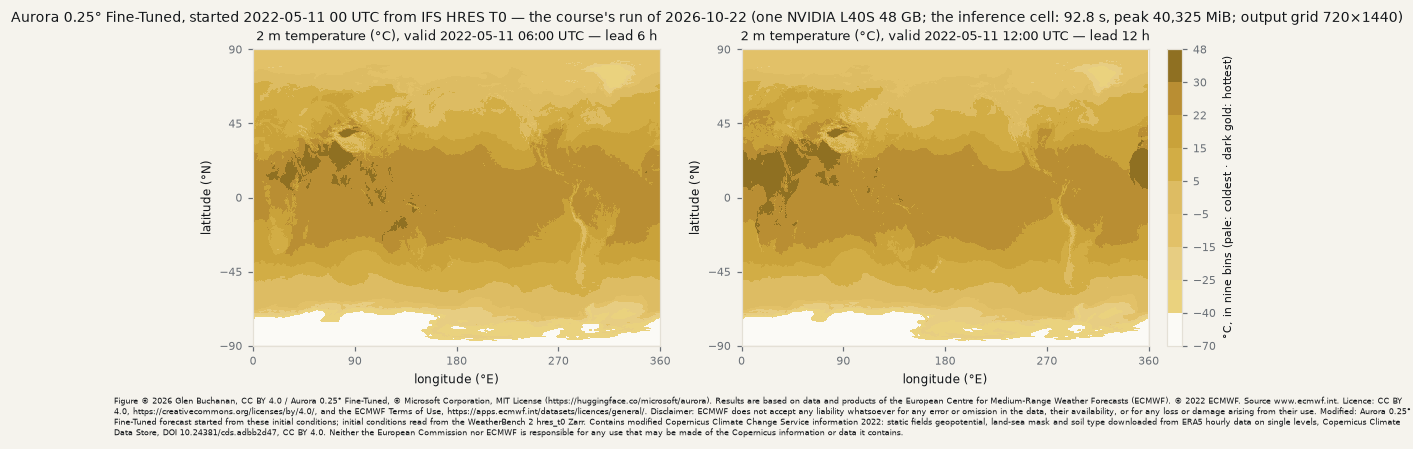

*The recorded output, re-plotted: 2 m temperature at lead 6 h and 12 h, read from the course's run record
— the course's 2026-10-22 run on an L40S 48 GB (the run cell below, 92.8 s at 40,325 MiB) — in nine colour bins (nothing is re-run). Figure © 2026 Glen Buchanan, CC BY 4.0 / Aurora 0.25° Fine-Tuned © Microsoft Corporation, MIT / initial conditions © 2022 ECMWF,
CC BY 4.0 and the ECMWF Terms of Use / static fields: modified Copernicus Climate Change Service information 2022 — the full three-notice text is printed
under the figure. Your own run's figure appears under the next cell when `RUN_INFERENCE` is True.* 


In [ ]:
if not RUN_INFERENCE:
    print("inference skipped: RUN_INFERENCE = False (the laptop default). Set it to True on a GPU of at least 48 GB in an environment built "
          "from course/environment.yml plus course/environment-gpu.yml — Keras on the torch backend, as cell 4 sets it, so ONE framework is in "
          "the kernel — with a CDS account whose ERA5 terms are accepted, and with the kernel started with LD_LIBRARY_PATH unset on a Deep "
          "Learning AMI (`env -u LD_LIBRARY_PATH jupyter …`: the image's system CUDA-12.x cuDNN shadows the torch wheel's and the model fails "
          "to load; smoke run 2026-10-22). The laptop environment carries none of the GPU extras.")
else:
    torch = importlib.import_module("torch")                     # GPU-step extras, loaded by name: pinned in environment-gpu.yml
    aurora = importlib.import_module("aurora")
    cdsapi = importlib.import_module("cdsapi")
    assert torch.cuda.is_available(), "no CUDA device: the fine-tuned 0.25° model needs about 40–48 GB of GPU memory"
    out_dir = Path("outputs"); out_dir.mkdir(exist_ok=True)

    # (1) the two analysis frames from the hres_t0 store — 6 h before the start and the start itself (frames_at, 5b) — latitudes
    #     decreasing, contiguous (the vendor's _prepare helper; its example reads 00:00 and 06:00 and starts at 06 UTC)
    ds = xr.open_zarr(IC_SOURCE, storage_options={"token": "anon"}, chunks=None)
    missing = [t for t in frames_at if np.datetime64(t) not in ds.time.values]
    assert not missing, (f"the hres_t0 store holds no frame at {missing}: it runs {pd.Timestamp(ds.time.values[0]):%Y-%m-%d} to "
                         f"{pd.Timestamp(ds.time.values[-1]):%Y-%m-%d %H:%M} UTC — CASE_DATE must lie inside it")
    frames = ds.sel(time=frames_at).sortby("latitude", ascending=False)
    surf = {"2t": "2m_temperature", "10u": "10m_u_component_of_wind", "10v": "10m_v_component_of_wind", "msl": "mean_sea_level_pressure"}
    atmos = {"t": "temperature", "u": "u_component_of_wind", "v": "v_component_of_wind", "q": "specific_humidity", "z": "geopotential"}
    as_tensor = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float()

    # (2) the static fields: "not available in WeatherBench2, so we need to download them from ERA5" — the vendor's CDS request
    static_nc = out_dir / "era5-static-2023-01-01.nc"
    if not static_nc.exists():
        cdsapi.Client().retrieve("reanalysis-era5-single-levels",
                                 {"product_type": ["reanalysis"], "variable": ["geopotential", "land_sea_mask", "soil_type"],
                                  "year": ["2023"], "month": ["01"], "day": ["01"], "time": ["00:00"], "data_format": "netcdf"},
                                 str(static_nc))
    static = xr.open_dataset(static_nc).sortby("latitude", ascending=False)
    def static_field(name):
        a = static[name]
        for dim in ("time", "valid_time"):
            if dim in a.dims:
                a = a.isel({dim: 0})
        return as_tensor(a.values)

    batch = aurora.Batch(
        surf_vars={k: as_tensor(frames[v].values[None]) for k, v in surf.items()},
        static_vars={k: static_field(k) for k in ("z", "lsm", "slt")},
        atmos_vars={k: as_tensor(frames[v].values[None]) for k, v in atmos.items()},
        metadata=aurora.Metadata(lat=as_tensor(frames.latitude.values), lon=as_tensor(frames.longitude.values),
                                 time=(pd.Timestamp(frames.time.values[1]).to_pydatetime(),), atmos_levels=tuple(int(l) for l in frames.level.values)))

    # (3) the model, by checkpoint name, in evaluation mode, on the GPU
    model = aurora.Aurora()
    model.load_checkpoint("microsoft/aurora", CHECKPOINT)
    model.eval(); model = model.to("cuda")
    with torch.inference_mode():
        preds = [p.to("cpu") for p in aurora.rollout(model, batch, steps=ROLLOUT_STEPS)]
    model = model.to("cpu")

    # (4) output on the PREDICTION's grid: the model crops to an even latitude count (720 rows from 721 in), so the coordinates
    #     come from pred.metadata, never from the input frames
    lat_out, lon_out = preds[0].metadata.lat.numpy(), preds[0].metadata.lon.numpy()
    out = xr.Dataset({"t2m": (("lead_time", "latitude", "longitude"), np.stack([p.surf_vars["2t"][0, 0].numpy() for p in preds]))},
                     coords=dict(lead_time=lead_hours, latitude=lat_out, longitude=lon_out))
    out.to_zarr(out_dir / f"aurora_{case:%Y%m%d}.zarr", mode="w")
    fig, axes = plt.subplots(1, ROLLOUT_STEPS, figsize=(5.5 * ROLLOUT_STEPS, 3.2))
    for ax, p, lh in zip(np.atleast_1d(axes), preds, lead_hours):
        ax.imshow(p.surf_vars["2t"][0, 0].numpy() - 273.15, cmap="RdPu", extent=[0, 360, -90, 90], aspect="auto")
        ax.set_title(f"2 m temperature (°C), {p.metadata.time[0]:%Y-%m-%d %H:%M} UTC, lead {lh} h", fontsize=8)
    cite_aurora(fig, case.year); plt.tight_layout()
    print(f"ran {ROLLOUT_STEPS} steps from {case:%Y-%m-%d}; output grid {lat_out.size}×{lon_out.size} (input {frames.latitude.size}×{frames.longitude.size}); "
          f"written to outputs/; figure credited with the three notices (Microsoft MIT · ECMWF · Copernicus)")

### 5d Condition (1): is this case represented in the model's training record?

A date is only a proxy; the question is whether the *state* — this regime, at this intensity, in this era of the analysis system — is in
the record. Storm Ciarán was "a valuable out-of-sample test for the ML-models because their training datasets all end before the beginning
of 2023", and "record-breaking": "all of the machine learning models underestimate the peak amplitude of winds associated with the storm".
A date inside the fine-tuning range is in-sample, and a forecast there shows nothing about skill; a held-out date can still sit at the edge
of what the record contains; a date after the record ends is outside it, and no state check can be made from a store that stops before it.

The next cell reads the case's two frames from the same `hres_t0` store the run starts from (read date and version stamp printed first)
and prints four numbers — the deepest low (minimum mean sea-level pressure), the strongest 10 m wind, the coldest and the warmest 2 m
temperature — over the **globe** and over the course's own **Front Range box** (`FRONT_RANGE`), each beside the range of the same numbers
over the same fortnight of each fine-tuning year the record holds (±`STATE_WINDOW_DAYS` days, at the two frame hours, 2019–2021; May 2018
precedes the Jul 2018 start). Inside on all four, the state is ordinary for its season at that scale; outside on one, say whether the
sample or the record is what the number exceeds. The global line is set by Antarctic cold, Southern Ocean lows and subtropical heat and
cannot see a Front Range regime; the box line sees the box's intensity, not the pattern behind it — evidence with its limits printed. For
the contrast case the store holds no frame, and the cell says so.

### 5e Condition (2): has the model's skill been evaluated at this lead time?

Skill is a verified number per lead time, or it is a vendor claim. WeatherBench 2 scores "data-driven global weather models" "based on
established practices for evaluating weather forecasts at leading operational weather centers", and lists "Aurora" (operational IFS
initial conditions, 0.25°). The cell reads that row's lead-time axis live, so the evaluated range is something the notebook read, not
something it was told; if the file cannot be read, the cell says so and types no axis in — Entry 21 cannot be completed from that run.
When this course was written (file read 2026-10-29), that axis ran from 6 h to 240 h in 6-hour steps: 10 days and no further. That is a reference point, not evidence: if the printed line differs, the printed line is right, and Entry 21 is scored on it.
Three checks precede the read, and the cell prints each as a `check` line with PASS or FAIL: the checkpoint (the row scores the fine-tuned model), the initial-condition source (operational IFS HRES T0) and the start hour, because the benchmark evaluates forecasts
initialized at 00 and 12 UTC (Rasp et al. 2023, §3.1 and §4.1) — so by its protocol a 06 UTC start lies off the row's axis at every lead
time. An independent community benchmark of this kind is what NSF NCAR's own **benchmarking and evaluation** focus area calls for — "transparent comparison, rigorous validation, and reproducible evaluation" — and it is the house reason this course verifies before it trusts. 


In [ ]:
# Condition (1), the state: each case's two frames against the same fortnight of each fine-tuning year, read over HTTPS from the SAME
# hres_t0 store the run starts from (nothing from it is redistributed). Four numbers per frame at two scales — the globe and the course's
# Front Range box — against a declared sample, labelled as one. The read date and the store's version stamp print first, so two learners
# a year apart can see why their numbers differ, if they do.
IC_HTTPS = IC_SOURCE.replace("gs://", "https://storage.googleapis.com/")
STATE_NUMBERS = {"deepest low (min MSLP), hPa": ("mean_sea_level_pressure", "min", 0.01),
                 "strongest 10 m wind, m/s":   ("10m_wind_speed", "max", 1.0),
                 "coldest 2 m temperature, °C": ("2m_temperature", "min", 1.0),
                 "warmest 2 m temperature, °C": ("2m_temperature", "max", 1.0)}
SCOPES = {"GLOBAL": None, "FRONT RANGE BOX": FRONT_RANGE}          # the box is Module 2's: lat 38.5–40.5 °N, lon 253.75–256.25 °E

def version_stamp(url):
    """Read date plus the object's HTTP Last-Modified and ETag — the version of a remote file that can change under the course."""
    with urllib.request.urlopen(urllib.request.Request(url, method="HEAD"), timeout=60) as r:
        return f"read {datetime.now(timezone.utc):%Y-%m-%d} UTC · Last-Modified {r.headers.get('Last-Modified')} · ETag {r.headers.get('ETag')}"

def state_numbers(frame, box=None):
    if box is not None:
        frame = frame.sel(latitude=box["lat"], longitude=box["lon"])       # latitudes ascend in this store, as the slice expects
    out = {}
    for label, (var, how, scale) in STATE_NUMBERS.items():
        v = float(getattr(frame[var], how)()) * scale
        out[label] = v - 273.15 if "temperature" in label else v
    return out

def state_block(hres, case, frames_at, label):
    """The state lines for one case — or the reason the store cannot give them."""
    print(f"CONDITION (1), THE STATE — {label}")
    last = pd.Timestamp(hres.time.values[-1])
    missing = [t for t in frames_at if np.datetime64(t) not in hres.time.values]
    if missing:
        print(f"  the store's last frame is {last:%Y-%m-%d %H:%M} UTC; it holds no frame at {', '.join(f'{t:%Y-%m-%d %H:%M}' for t in missing)}: "
              "the state is NOT DETERMINABLE from this store — condition (1) stands on the date line alone for this case")
        return
    # the sample holds BOTH frame hours: a global extreme such as the warmest 2 m temperature depends on the hour of day, so each case
    # frame is read against frames at its own hour
    ref_times = [t + pd.Timedelta(hours=dh) for y in range(FINE_TUNING_USED[0].year, FINE_TUNING_USED[1].year + 1)
                 for t in pd.date_range(case.replace(year=y) - pd.Timedelta(days=STATE_WINDOW_DAYS),
                                        case.replace(year=y) + pd.Timedelta(days=STATE_WINDOW_DAYS), freq="D")
                 for dh in (-6, 0)
                 if FINE_TUNING_USED[0] <= (t + pd.Timedelta(hours=dh)).normalize() <= FINE_TUNING_USED[1] and t + pd.Timedelta(hours=dh) not in frames_at]
    sub = hres[sorted({v for v, _, _ in STATE_NUMBERS.values()})].sel(time=frames_at + ref_times).load()
    print(f"  reference sample: {len(ref_times)} frames at {frames_at[0]:%H:%M} and {frames_at[1]:%H:%M} UTC (the two frame hours), ±{STATE_WINDOW_DAYS} days "
          f"of {case:%d %B} in each fine-tuning year {sorted({t.year for t in ref_times})} (Jul 2018–2021 is the record; this is a sample of it, not the record)")
    for scope, box in SCOPES.items():
        case_nums = {t: state_numbers(sub.sel(time=t), box) for t in frames_at}
        ref_nums = pd.DataFrame([state_numbers(sub.sel(time=t), box) for t in ref_times], index=ref_times)
        outside = 0
        print(f"  {scope}" + ("" if box is None else f" (lat {box['lat'].start}–{box['lat'].stop} °N, lon {box['lon'].start}–{box['lon'].stop} °E)"))
        for lab in STATE_NUMBERS:
            lo, hi = ref_nums[lab].min(), ref_nums[lab].max()
            vals = [case_nums[t][lab] for t in frames_at]
            inside = all(lo <= v <= hi for v in vals)
            outside += 0 if inside else 1
            print(f"    {lab:29s} case frames {vals[0]:7.1f} {vals[1]:7.1f}   sample range {lo:7.1f} to {hi:7.1f}   → "
                  + ("inside the sampled range" if inside else "OUTSIDE the sampled range — say whether the sample or the record is what it exceeds"))
        print("    reading: " + ("all four numbers sit inside the same-season sample — an ordinary state for its season at this scale" if outside == 0 else
                                 f"{outside} of four numbers {'falls' if outside == 1 else 'fall'} outside a {len(ref_times)}-frame sample; a small sample is exceeded before the record is")
              + ("; four global extremes do not read the regime" if box is None else "; the box's intensity, not the pattern that produced it"))

try:
    print(f"hres_t0 store {IC_HTTPS.rsplit('/', 1)[-1]}: {version_stamp(IC_HTTPS + '/.zmetadata')}")
    hres = xr.open_zarr(IC_HTTPS, chunks=None, consolidated=True)
    store_last = pd.Timestamp(hres.time.values[-1])
    print(f"  store time axis: {pd.Timestamp(hres.time.values[0]):%Y-%m-%d %H:%M} to {store_last:%Y-%m-%d %H:%M} UTC" +
          (" — matches IC_STORE_END, the end the run record (5b) used" if store_last == IC_STORE_END else
           f" — DIFFERS from IC_STORE_END {IC_STORE_END:%Y-%m-%d %H:%M} UTC in 5b: a case between the two has a wrong initial-conditions line in its run record; update IC_STORE_END and re-run 5b"))
    state_block(hres, case, frames_at, "DEFAULT CASE")
    print()
    state_block(hres, case_c, frames_at_c, "CONTRAST CASE")
except Exception as e:   # no network, or the store moved: say so — nothing is typed in
    print(f"could not read the hres_t0 store for the state check ({type(e).__name__}: {e}). Re-run this cell online; without these lines "
          "the state question in Entry 21 is answered 'not determinable from this run'.")

# Condition (2): read the WeatherBench 2 evaluation of the Aurora row LIVE — the lead-time axis is the answer to "evaluated at which lead times?".
WB2_FILE = "https://storage.googleapis.com/weatherbench2/benchmark_results/aurora_vs_hres_t0_1440x721_2022.nc"
print()

def lead_block(lt, case, frames, lead_hours, init_scored, label):
    """Condition (2) for one case: the three checks the WeatherBench 2 'Aurora' row rests on (the 5b record's condition (2) line), each PASS or
    FAIL from the record's own values, then the lead times against the axis. Each check can fail: a pretrained checkpoint; a start that is not
    operational IFS (an ERA5 store is the pretrained checkpoint's scorecard, not this row's); a start hour the row does not score."""
    ckpt_ok = "finetuned" in CHECKPOINT.lower()
    from_store = store_holds(frames)
    ic_ifs = ("hres_t0" in IC_SOURCE.lower() or "ifs" in IC_SOURCE.lower()) if from_store else True   # a live start is Earth2Studio IFS() by the record
    print(f"  {label}")
    print(f"    check 1 — checkpoint: {CHECKPOINT} = the row's fine-tuned model → " + ("PASS" if ckpt_ok else "FAIL — the row scores the fine-tuned checkpoint only"))
    print(f"    check 2 — initial conditions: IFS HRES T0 ({'the hres_t0 store' if from_store else 'a live IFS start via Earth2Studio IFS()'}) = operational IFS → "
          + ("PASS" if ic_ifs else f"FAIL — {IC_SOURCE} is not an operational-IFS source"))
    print(f"    check 3 — start hour {case:%H} UTC in {WB2_INIT_HOURS} UTC → " + ("PASS — a start hour the row scores (00/12 UTC)" if init_scored else
          "FAIL — NOT a start hour the row scores (00/12 UTC only): condition (2) unmet for this run at every lead time"))
    shown = lead_hours if len(lead_hours) <= 3 else [lead_hours[0], lead_hours[1], lead_hours[-1]]     # a long rollout: its first two and its last
    for h_ in shown:
        inside = (lt.min() <= h_ <= lt.max())
        print(f"    this run's lead time {h_} h: {'INSIDE the evaluated axis' if inside else 'OUTSIDE the evaluated axis — condition (2) unmet'}"
              + ("" if init_scored else " (and the start hour already failed)"))
    if len(lead_hours) > 3:
        n_out = sum(1 for h_ in lead_hours if not (lt.min() <= h_ <= lt.max()))
        print(f"    ({len(lead_hours)} lead times in all; {n_out} of them OUTSIDE the evaluated axis)")

try:
    local = Path(tempfile.mkdtemp()) / "aurora_vs_hres_t0_1440x721_2022.nc"
    _, headers = urllib.request.urlretrieve(WB2_FILE, local)
    wb2 = xr.open_dataset(local)
    lt = wb2["lead_time"].values
    print(f"WeatherBench 2 file read: {WB2_FILE.rsplit('/', 1)[-1]} — read {datetime.now(timezone.utc):%Y-%m-%d} UTC · Last-Modified {headers.get('Last-Modified')} · ETag {headers.get('ETag')}")
    print(f"  lead_time axis: {lt.min()} h to {lt.max()} h in {lt.size} steps of {int(np.diff(lt).min())} h  →  evaluated to {lt.max() / 24:g} days and no further")
    print(f"  regions: {wb2.region.size} (first: {list(wb2.region.values)[:4]}) · levels: {list(wb2.level.values)}")
    z500 = wb2["rmse.geopotential"].sel(level=500, region="global")
    print("  Z500 RMSE, global, by lead time (the file carries no units attribute):")
    for h_ in [24, 72, 120, 168, 240]:
        print(f"    {h_:4d} h  {float(z500.sel(lead_time=h_)):.1f}")
    lead_block(lt, case, frames_at, lead_hours, init_scored, "DEFAULT CASE")
    lead_block(lt, case_c, frames_at_c, lead_hours_c, init_scored_c, "CONTRAST CASE")
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    ax.plot(lt / 24, z500.values, color="#5b6168", marker="o", ms=3, lw=1.4, label="Aurora row, WeatherBench 2 (third-party values)")
    ax.axvspan(0, lead_hours[-1] / 24, color="#E7CD82", zorder=0, lw=0, label="this run: start to its last lead time")   # the course's element, in gold
    for h_ in lead_hours:
        ax.axvline(h_ / 24, color="#C9A23A", lw=1.2, ls="--")
    ax.axvline(lead_hours_c[-1] / 24, color="#7f7f7f", lw=1, ls=":", label="contrast case's last lead time")
    ax.legend(fontsize=7, loc="upper left")
    ax.set(xlabel="lead time [days]", ylabel="Z500 RMSE (global, 2022, vs HRES T0)",
           title="Aurora row, WeatherBench 2: the evaluated lead-time axis\n(dashed: the default case's lead times; dotted: the contrast case's last)")
    ax.title.set_fontsize(9)
    cite_wb2(fig); plt.tight_layout(); save_fig(fig, "5e-lead-time-axis")
except Exception as e:   # no network, or the bucket moved: say so — the course does not type the axis in, so no number follows
    print(f"could not read the WeatherBench 2 file ({type(e).__name__}: {e}). Re-run this cell online: Entry 21's condition (2) cannot be "
          "completed from this run.")


:::{note}
**Exercise 21 — the two do-not-trust conditions, for this run.** For the **default case**: (1) from the record's `condition (1) date` line,
is it in-sample, held out or outside — and from the state block, how many of the four numbers sit inside the sampled range on the global
line and on the Front Range line, what does a sample of that size let you say, and what does neither line read? (2) From the WeatherBench 2 block: the evaluated axis
(first, last, step), whether this run's lead times lie inside it, and the three checks that had to pass before the axis could be read.
(3) For the **contrast case**, paste its `condition (1) date` line, its `initialization` line, its state line and its `lead time … OUTSIDE`
lines, and say which condition each line fires. Then the verdict: would you hand the default run's output to the forecaster?
→ **Handbook entry 21**
:::

### 5f Further warning signs — discussed, not tested

**Two other scorecards.** Earth2Studio's Aurora scorecard is for the *pretrained* checkpoint started from ERA5, scored by the wrapper's
own vendor: the run record's checkpoint line rules it out before any axis is read. FourCastNet 3 claims calibration "even at extended
lead times of up to 60 days"; WeatherBench 2 lists no FourCastNet row and this course found no independent per-lead-time scorecard, so
for FCN3 condition (2) has only the vendor's claim to answer from. Absence from one benchmark and this course's search is not proof that no
evaluation exists; it is the lookup returning nothing.

**Physical consistency:** such forecasts "do not have the fidelity and physical consistency of physics-based models", and their advantage
on deterministic scores "can be at least partly attributed to these peculiarities": a smoother field scores better on RMSE without being a
better forecast. 

**Drift with lead time:** "increasing forecast smoothness and bias drift with forecast lead time" are "current drawbacks of ML-based
forecasts". 

**Input mismatch:** a model started from data it was not fine-tuned on "will likely give sensible predictions, but performance may not be
optimal anymore": it runs, it looks plausible, and the scorecard for the right start does not apply. 


## Part 6: Evaluate and justify — your final decision

Unidata's closing instruction: "No matter your final decision, the most important aspect is your ability to justify it using data and a
robust evaluation. … Rarely is there a single correct answer." The *justify* step guards against *a model chosen for its sophistication
rather than its measured performance and cost*, and a neural network is the rung where that failure is most tempting.

Write your recommendation in three parts, each claim pointing at a number in Entries 12–21 and quoting the line it rests on. These are the questions each part answers:

1. **The network, to the forecaster.** Which model reached the test and why (Entry 16); is its tested skill distinguishable from none (the 3g interval lines); if a network was promoted, did the gain come from the model class (trial 1), the inputs (trial 2) or the operating point (the AP columns, the control line); what does it cost that your Module 2 model does not?
2. **The AI weather model's output, to the same office.** Under which conditions would you hand it to a forecaster (Entries 20–21)?
3. **The one further change most likely to move the result**, and its cost: which parameter, whether the cache must be rebuilt, how long.

:::{note}
**Exercise 22 — the final decision.** Write the recommendation in the Handbook in the three labelled parts above. Every claim points at a
number already in Entries 12–21 and quotes the line it rests on — the two 3g `− base rate` interval lines (Entry 17), the register's final
`incumbent after N trials:` line and the verdict of its last row (Entry 16), the default case's `condition (1) date`, `initialization` and
`lead_time axis …` lines (Entry 21); a claim is scored on the line quoted under it. → **Handbook entry 22**
:::


## Summary

The spine was walked a second time on Module 2's members with a model that has an epoch count: stopped at its validation minimum on whole
held-out members, scored on member-grouped folds with the transforms refit inside every fold, compared by the paired test with an AP guard
and a no-skill control, and tested against no skill on Module 2's test members a second time (a second look, not a blind test). Three predictions were explained from a stated baseline, read as sign and size,
on a network named as a method demonstration. For one AI weather model the run record was written first, the case's state read from the
run's own store at two scales, and the two conditions read for the default case and seen firing on a printed contrast case; the run cell
was executed once by the course (2026-10-22, one L40S 48 GB; its record is kept by the author, available on request), its recorded output is re-plotted in 5c, and on a laptop it stays off. The design decisions are tabled in 2a. 

### What's next?

The quiz: ten items, two per objective; then three booster questions at two days, two weeks and two months — the last on the two
do-not-trust conditions.

## Additional resources

**Data, code and models the notebook uses** (required citations and licences):

| Source | Licence | What the course takes |
|---|---|---|
| Community Earth System Model v2 Large Ensemble (CESM2 LENS) was accessed on 2026-10-20 from https://registry.opendata.aws/ncar-cesm2-lens. — Registry of Open Data on AWS; documentation DOI 10.26024/y48t-q717 (Grover & Banihirwe 2021, NSF NCAR CISL, https://doi.org/10.26024/y48t-q717) | UCAR Data Terms of Use (CC BY 4.0). Results based on the CESM2 Large Ensemble acknowledge the CESM2 Large Ensemble Community Project and the IBS Center for Climate Physics, South Korea | the member-winter table (Module 2's cache) |
| Rodgers, K. B. et al. (2021). Ubiquity of human-induced changes in climate variability. *Earth System Dynamics* 12, 1393–1411. https://doi.org/10.5194/esd-12-1393-2021 | CC BY 4.0 | the ensemble's paper, cited under every LENS figure |
| NSF Unidata, *Supervised Machine Learning Readiness*. https://github.com/Unidata/supervised-ml-readiness | Apache-2.0 | the spine, handbook and rubric shape |
| Keras 3: *Training & evaluation with the built-in methods*; `callbacks.EarlyStopping`. https://keras.io/ | Apache-2.0 | the network, early stopping |
| TensorFlow tutorials, *Integrated gradients*. https://www.tensorflow.org/tutorials/interpretability/integrated_gradients; method: Sundararajan, Taly & Yan (2017), arXiv:1703.01365 | CC BY 4.0; code Apache-2.0 | the attribution method (4a–4b) |
| Aurora weights, https://huggingface.co/microsoft/aurora; docs *Predictions for HRES T0*, https://microsoft.github.io/aurora/example_hres_t0.html | MIT | the inference case (5c) |
| IFS HRES T0 initial conditions: gs://weatherbench2/datasets/hres_t0/ | © ECMWF, CC BY 4.0 and the ECMWF terms | the two frames; the 5d state sample |
| Static fields: ERA5 hourly data on single levels, Copernicus CDS, DOI 10.24381/cds.adbb2d47 | CC BY 4.0 (Copernicus licence) | z, lsm, slt for the model |
| WeatherBench 2 results, gs://weatherbench2/benchmark_results/; site https://sites.research.google/weatherbench/ | Google Terms; no licence published on the result files | the Aurora row's lead-time axis, read live (5e) |

**Readings the notebook quotes:**

| Reading | Licence |
|---|---|
| Google Machine Learning Crash Course, *Neural networks*. https://developers.google.com/machine-learning/crash-course/neural-networks | CC BY 4.0 |
| Mamalakis, Barnes & Ebert-Uphoff (2022). Investigating the fidelity of explainable AI methods for CNNs in geoscience. arXiv:2202.03407v1 — the copy quoted (published as *AIES* 1(4), e220012 under the AMS reuse licence — cited, not quoted) | CC BY 4.0 (the arXiv v1 text) |
| Mamalakis, Barnes & Ebert-Uphoff (2022). Carefully choose the baseline. arXiv:2208.09473v1 — the copy quoted (published as *AIES* 2(1), e220058 under the AMS reuse licence — cited, not quoted) | CC BY 4.0 (the arXiv v1 text) |
| Dillon, LaRiviere, Lundberg, Roth & Syrgkanis. *Be careful when interpreting predictive models in search of causal insights*. SHAP documentation, https://shap.readthedocs.io/ | MIT |
| Schreck, J. et al. (2024). CREDIT. arXiv:2411.07814; software NCAR/miles-credit | CC BY 4.0; Apache-2.0 |
| Bodnar, C. et al. (2025). A foundation model for the Earth system. *Nature* 641, 1180–1187. https://doi.org/10.1038/s41586-025-09005-y | CC BY-NC-ND 4.0 (cited) |
| Rasp, S. et al. (2023). WeatherBench 2. arXiv:2308.15560 | CC BY 4.0 |
| Bonavita, M. (2023). On some limitations of data-driven weather forecasting models. arXiv:2309.08473 | CC BY 4.0 |
| Ben Bouallègue, Z. et al. (2023). The rise of data-driven weather forecasting. arXiv:2307.10128 | CC BY-SA 4.0 (quoted, not adapted) |
| Charlton-Perez, A. J. et al. (2023). Do AI models produce better weather forecasts than physics-based models? Storm Ciarán. arXiv:2312.02658 | CC BY 4.0 |

**Further reading** (not quoted in this notebook; Module 2's physical prior): Stagge, J. H. et al. (2023). Orographic amplification of El Niño teleconnections on winter precipitation across the Intermountain West. *Nature Water* 1, 1016–1026. https://doi.org/10.1038/s44221-023-00163-9 (CC BY 4.0).
